# Competencia — experimentos de modelado

In [9]:
from pathlib import Path
import gc

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

import preprocesamiento as prep
import feature_engineering as fe

PROYECTO = Path.cwd().resolve()

print("Proyecto:", PROYECTO)
print("Preparación disponible:", (PROYECTO / "preprocesamiento.py").is_file())
print("Feature engineering disponible:", (PROYECTO / "feature_engineering.py").is_file())

Proyecto: /Users/manuelmarasco/Desktop/dmeyf402
Preparación disponible: True
Feature engineering disponible: True


In [17]:
RUTAS_POSIBLES = [
    PROYECTO / "data" / "competencia_01_crudo.csv",
    PROYECTO / "competencia_01_crudo.csv",
    Path(
        "/Users/manuelmarasco/Library/CloudStorage/"
        "GoogleDrive-hola@manuelmarasco.com/"
        "Mi unidad/DMEyF/2026/notebooks/data/"
        "competencia_01_crudo.csv"
    ),
]

RUTA_FUENTE = next(
    (ruta for ruta in RUTAS_POSIBLES if ruta.is_file()),
    None,
)

if RUTA_FUENTE is None:
    raise FileNotFoundError(
        "No se encontró competencia_01_crudo.csv. "
        "Colocarlo dentro de la carpeta data/ del proyecto."
    )

print("Base encontrada:", RUTA_FUENTE)

Base encontrada: /Users/manuelmarasco/Library/CloudStorage/GoogleDrive-hola@manuelmarasco.com/Mi unidad/DMEyF/2026/notebooks/data/competencia_01_crudo.csv


In [12]:
base_original = prep.cargar_competencia_01(RUTA_FUENTE)

print("Filas:", len(base_original))
print("Columnas:", base_original.shape[1])
print("Meses:", sorted(base_original["foto_mes"].unique()))

Filas: 983061
Columnas: 154
Meses: [np.int64(202103), np.int64(202104), np.int64(202105), np.int64(202106), np.int64(202107), np.int64(202108)]


In [13]:
base_preprocesada, reporte_correcciones = prep.preprocesar_competencia_01(
    base_original
)

del base_original
gc.collect()

display(reporte_correcciones)

,correccion,filas_corregidas
0,Master_limite_financiacion_fue_corregido,4245
1,Visa_limite_financiacion_fue_corregido,1101


In [14]:
auditoria_preprocesamiento = prep.auditar_preprocesamiento(
    base_preprocesada
)

display(auditoria_preprocesamiento)

,foto_mes,filas,targets_disponibles,casos_baja2
0,202103,162900,162900,960
1,202104,163284,163284,1139
2,202105,163768,163768,870
3,202106,164114,164114,1098
4,202107,164348,0,0
5,202108,164647,0,0


In [15]:
RUTA_FEATURES = PROYECTO / "features_candidato_fe.csv"

features_baseline = prep.cargar_lista_features(RUTA_FEATURES)

entrada_fe, features_entrada = prep.seleccionar_entrada_feature_engineering(
    base_preprocesada,
    features_baseline,
)

entrada_fe, infinitos_convertidos = prep.convertir_infinitos_en_nulos(
    entrada_fe,
    features_entrada,
    copiar=False,
)

del base_preprocesada
gc.collect()

print("Features finales registradas:", len(features_baseline))
print("Features de entrada:", len(features_entrada))
print("Infinitos convertidos en nulos:", infinitos_convertidos)

Features finales registradas: 238
Features de entrada: 156
Infinitos convertidos en nulos: 0


In [16]:
base_modelado, features_temporales, features_carga = (
    fe.construir_features_candidato(entrada_fe)
)

del entrada_fe
gc.collect()

features_generadas = (
    features_entrada
    + features_temporales
    + features_carga
)

features_faltantes = [
    feature
    for feature in features_baseline
    if feature not in base_modelado.columns
]

print("Filas:", len(base_modelado))
print("Features de entrada:", len(features_entrada))
print("Features temporales:", len(features_temporales))
print("Features de carga financiera:", len(features_carga))
print("Features totales:", len(features_generadas))
print("Coincide el orden esperado:", features_generadas == features_baseline)
print("Features faltantes:", len(features_faltantes))

Filas: 983061
Features de entrada: 156
Features temporales: 47
Features de carga financiera: 35
Features totales: 238
Coincide el orden esperado: True
Features faltantes: 0


In [18]:
auditoria_features = prep.auditar_features(
    base=base_modelado,
    features_finales=features_baseline,
    features_lag=features_temporales,
    features_carga=features_carga,
    variables_lag=fe.VARIABLES_LAG1,
)

display(
    pd.Series(
        auditoria_features,
        name="resultado",
    ).to_frame()
)

,resultado
filas,983061
features_finales,238
features_faltantes,0
features_lag_delta_eventos,47
features_carga_financiera,35
features_generadas,82
valores_infinitos,0
discrepancias_continuidad,0
lags_con_discrepancias,0


In [21]:
FOLDS_TEMPORALES = [
    {
        "entrenamiento": [202103, 202104],
        "validacion": 202105,
    },
    {
        "entrenamiento": [202103, 202104, 202105],
        "validacion": 202106,
    },
]

resumen_folds = []

for fold in FOLDS_TEMPORALES:
    mascara_train = base_modelado["foto_mes"].isin(
        fold["entrenamiento"]
    )
    mascara_valid = base_modelado["foto_mes"].eq(
        fold["validacion"]
    )

    resumen_folds.append(
        {
            "entrenamiento": "-".join(
                map(str, fold["entrenamiento"])
            ),
            "validacion": fold["validacion"],
            "filas_train": int(mascara_train.sum()),
            "baja2_train": int(
                base_modelado.loc[
                    mascara_train,
                    "target_baja2",
                ].sum()
            ),
            "filas_validacion": int(mascara_valid.sum()),
            "baja2_validacion": int(
                base_modelado.loc[
                    mascara_valid,
                    "target_baja2",
                ].sum()
            ),
        }
    )

display(pd.DataFrame(resumen_folds))

,entrenamiento,validacion,filas_train,baja2_train,filas_validacion,baja2_validacion
0,202103-202104,202105,326184,2099,163768,870
1,202103-202104-202105,202106,489952,2969,164114,1098


In [22]:
GANANCIA_BAJA2 = 1_072_500
COSTO_ESTIMULO = 27_500

UMBRAL_RENTABLE = (
    COSTO_ESTIMULO
    / (GANANCIA_BAJA2 + COSTO_ESTIMULO)
)


def evaluar_predicciones(
    y_binaria,
    clase_ternaria,
    probabilidades,
):
    y_binaria = np.asarray(y_binaria, dtype="int8")
    clase_ternaria = np.asarray(clase_ternaria)
    probabilidades = np.asarray(probabilidades)

    estimular = probabilidades >= UMBRAL_RENTABLE

    ganancia_por_cliente = np.where(
        clase_ternaria == "BAJA+2",
        GANANCIA_BAJA2,
        -COSTO_ESTIMULO,
    )

    return {
        "ganancia": float(
            ganancia_por_cliente[estimular].sum()
        ),
        "auc": float(
            roc_auc_score(y_binaria, probabilidades)
        ),
        "clientes_estimulados": int(estimular.sum()),
    }


print("Umbral rentable:", UMBRAL_RENTABLE)

Umbral rentable: 0.025


# Modelo Base

In [23]:
SEMILLAS = [
    100129,
    100183,
    100151,
    500041,
    900007,
]

PARAMETROS_BASE = {
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "max_depth": 12,
    "num_leaves": 57,
    "learning_rate": 0.014449396240655157,
    "min_data_in_leaf": 1614,
    "feature_fraction": 0.2613620757159252,
    "bagging_fraction": 0.5276823217951291,
    "bagging_freq": 1,
    "lambda_l1": 6.957248085997317e-05,
    "lambda_l2": 4.968141077185522e-06,
    "min_gain_to_split": 1.5074952598260436,
    "max_bin": 31,
    "feature_pre_filter": False,
    "verbosity": -1,
}

MAX_ITERACIONES = 2000
EARLY_STOPPING = 100

print("Semillas:", len(SEMILLAS))
print("Máximo de iteraciones:", MAX_ITERACIONES)
print("Early stopping:", EARLY_STOPPING)

Semillas: 5
Máximo de iteraciones: 2000
Early stopping: 100


# Entrenamiento y validación

In [24]:
MESES_TRAIN_PRINCIPAL = [
    202103,
    202104,
    202105,
]

MES_VALIDACION_PRINCIPAL = 202106

mascara_train = base_modelado["foto_mes"].isin(
    MESES_TRAIN_PRINCIPAL
)
mascara_valid = base_modelado["foto_mes"].eq(
    MES_VALIDACION_PRINCIPAL
)

X_train_base = base_modelado.loc[
    mascara_train,
    features_baseline,
]

y_train_base = (
    base_modelado.loc[
        mascara_train,
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_base = base_modelado.loc[
    mascara_valid,
    features_baseline,
]

y_valid_base = (
    base_modelado.loc[
        mascara_valid,
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

clase_valid_base = (
    base_modelado.loc[
        mascara_valid,
        "clase_ternaria",
    ]
    .astype("object")
    .to_numpy()
)

print("Train:", X_train_base.shape)
print("BAJA+2 en train:", int(y_train_base.sum()))
print("Validación:", X_valid_base.shape)
print("BAJA+2 en validación:", int(y_valid_base.sum()))

Train: (489952, 238)
BAJA+2 en train: 2969
Validación: (164114, 238)
BAJA+2 en validación: 1098


# Modelo Control 

In [25]:
SEMILLA_PRUEBA = 100129

parametros_prueba = {
    **PARAMETROS_BASE,
    "seed": SEMILLA_PRUEBA,
    "feature_fraction_seed": SEMILLA_PRUEBA,
    "bagging_seed": SEMILLA_PRUEBA,
    "data_random_seed": SEMILLA_PRUEBA,
    "deterministic": True,
    "force_col_wise": True,
}

dataset_train = lgb.Dataset(
    X_train_base,
    label=y_train_base,
)

dataset_valid = lgb.Dataset(
    X_valid_base,
    label=y_valid_base,
    reference=dataset_train,
)

modelo_prueba = lgb.train(
    params=parametros_prueba,
    train_set=dataset_train,
    num_boost_round=MAX_ITERACIONES,
    valid_sets=[dataset_valid],
    valid_names=["validacion"],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=EARLY_STOPPING,
            verbose=False,
        ),
        lgb.log_evaluation(period=100),
    ],
)

probabilidades_prueba = modelo_prueba.predict(
    X_valid_base,
    num_iteration=modelo_prueba.best_iteration,
)

resultado_prueba = evaluar_predicciones(
    y_binaria=y_valid_base,
    clase_ternaria=clase_valid_base,
    probabilidades=probabilidades_prueba,
)

resultado_prueba["iteraciones"] = (
    modelo_prueba.best_iteration
)

display(pd.DataFrame([resultado_prueba]))

[100]	validacion's auc: 0.899705
[200]	validacion's auc: 0.90186
[300]	validacion's auc: 0.902632
[400]	validacion's auc: 0.903049


,ganancia,auc,clientes_estimulados,iteraciones
0,360387500.0,0.903628,8495,362


Esta celda reutiliza el modelo base, solamente entrena las cuatro semillas restantes.

In [26]:
predicciones_base = {
    SEMILLA_PRUEBA: probabilidades_prueba
}

importancias_base = {
    SEMILLA_PRUEBA: modelo_prueba.feature_importance(
        importance_type="gain"
    )
}

fila_prueba = {
    "semilla": SEMILLA_PRUEBA,
    "ganancia": resultado_prueba["ganancia"],
    "auc": resultado_prueba["auc"],
    "clientes_estimulados": resultado_prueba[
        "clientes_estimulados"
    ],
    "iteraciones": resultado_prueba["iteraciones"],
}

filas_metricas_base = [fila_prueba]

for semilla in SEMILLAS:
    if semilla == SEMILLA_PRUEBA:
        continue

    parametros_semilla = {
        **PARAMETROS_BASE,
        "seed": semilla,
        "feature_fraction_seed": semilla,
        "bagging_seed": semilla,
        "data_random_seed": semilla,
        "deterministic": True,
        "force_col_wise": True,
    }

    dataset_train_semilla = lgb.Dataset(
        X_train_base,
        label=y_train_base,
    )

    dataset_valid_semilla = lgb.Dataset(
        X_valid_base,
        label=y_valid_base,
        reference=dataset_train_semilla,
    )

    modelo_semilla = lgb.train(
        params=parametros_semilla,
        train_set=dataset_train_semilla,
        num_boost_round=MAX_ITERACIONES,
        valid_sets=[dataset_valid_semilla],
        valid_names=["validacion"],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=EARLY_STOPPING,
                verbose=False,
            ),
            lgb.log_evaluation(period=0),
        ],
    )

    probabilidades = modelo_semilla.predict(
        X_valid_base,
        num_iteration=modelo_semilla.best_iteration,
    )

    metricas = evaluar_predicciones(
        y_binaria=y_valid_base,
        clase_ternaria=clase_valid_base,
        probabilidades=probabilidades,
    )

    predicciones_base[semilla] = probabilidades

    importancias_base[semilla] = (
        modelo_semilla.feature_importance(
            importance_type="gain"
        )
    )

    filas_metricas_base.append(
        {
            "semilla": semilla,
            **metricas,
            "iteraciones": modelo_semilla.best_iteration,
        }
    )

    print(
        f"Semilla {semilla} | "
        f"Ganancia {metricas['ganancia']:,.0f} | "
        f"AUC {metricas['auc']:.4f}"
    )

    del modelo_semilla
    del dataset_train_semilla
    del dataset_valid_semilla
    gc.collect()

metricas_semillas_base = (
    pd.DataFrame(filas_metricas_base)
    .sort_values("semilla")
    .reset_index(drop=True)
)

del modelo_prueba
del dataset_train
del dataset_valid
gc.collect()

display(metricas_semillas_base)

Semilla 100183 | Ganancia 358,215,000 | AUC 0.9038
Semilla 100151 | Ganancia 360,552,500 | AUC 0.9040
Semilla 500041 | Ganancia 366,822,500 | AUC 0.9048
Semilla 900007 | Ganancia 367,455,000 | AUC 0.9051


,semilla,ganancia,auc,clientes_estimulados,iteraciones
0,100129,360387500.0,0.903628,8495,362
1,100151,360552500.0,0.904042,8529,522
2,100183,358215000.0,0.903752,8374,269
3,500041,366822500.0,0.904824,8541,403
4,900007,367455000.0,0.905061,8518,403


In [27]:
matriz_predicciones_base = np.column_stack(
    [
        predicciones_base[semilla]
        for semilla in SEMILLAS
    ]
)

probabilidad_promedio_base = (
    matriz_predicciones_base.mean(axis=1)
)

probabilidad_mediana_base = np.median(
    matriz_predicciones_base,
    axis=1,
)

filas_ensemble_base = []

for metodo, probabilidades in [
    (
        "PROMEDIO_5_SEMILLAS",
        probabilidad_promedio_base,
    ),
    (
        "MEDIANA_5_SEMILLAS",
        probabilidad_mediana_base,
    ),
]:
    metricas = evaluar_predicciones(
        y_binaria=y_valid_base,
        clase_ternaria=clase_valid_base,
        probabilidades=probabilidades,
    )

    filas_ensemble_base.append(
        {
            "metodo": metodo,
            **metricas,
        }
    )

metricas_ensemble_base = pd.DataFrame(
    filas_ensemble_base
)

correlacion_semillas_base = pd.DataFrame(
    matriz_predicciones_base,
    columns=SEMILLAS,
).corr()

display(metricas_ensemble_base)
display(correlacion_semillas_base.round(4))

,metodo,ganancia,auc,clientes_estimulados
0,PROMEDIO_5_SEMILLAS,355960000.0,0.905267,8456
1,MEDIANA_5_SEMILLAS,363082500.0,0.905088,8397


,100129,100183,100151,500041,900007
100129,1.0000,0.9886,0.9864,0.9888,0.9894
100183,0.9886,1.0000,0.9808,0.9864,0.9870
100151,0.9864,0.9808,1.0000,0.9861,0.9866
500041,0.9888,0.9864,0.9861,1.0000,0.9888
900007,0.9894,0.9870,0.9866,0.9888,1.0000


In [28]:
def diagnosticar_ganancia(
    nombre,
    probabilidades,
    clase_ternaria,
):
    probabilidades = np.asarray(probabilidades)
    clases = np.asarray(clase_ternaria)

    orden = np.argsort(
        -probabilidades,
        kind="mergesort",
    )

    probabilidades_ordenadas = probabilidades[orden]
    clases_ordenadas = clases[orden]

    ganancia_fila = np.where(
        clases_ordenadas == "BAJA+2",
        GANANCIA_BAJA2,
        -COSTO_ESTIMULO,
    )

    ganancia_acumulada = np.cumsum(ganancia_fila)

    ganancias_con_cero = np.concatenate(
        [[0], ganancia_acumulada]
    )

    cantidad_optima = int(
        np.argmax(ganancias_con_cero)
    )

    if cantidad_optima == 0:
        umbral_diagnostico = np.inf
        ganancia_maxima = 0.0
        baja2_encontrados = 0
    else:
        umbral_diagnostico = float(
            probabilidades_ordenadas[
                cantidad_optima - 1
            ]
        )
        ganancia_maxima = float(
            ganancia_acumulada[
                cantidad_optima - 1
            ]
        )
        baja2_encontrados = int(
            (
                clases_ordenadas[:cantidad_optima]
                == "BAJA+2"
            ).sum()
        )

    resultado_fijo = evaluar_predicciones(
        y_binaria=y_valid_base,
        clase_ternaria=clase_valid_base,
        probabilidades=probabilidades,
    )

    return {
        "metodo": nombre,
        "ganancia_umbral_0025": resultado_fijo[
            "ganancia"
        ],
        "clientes_umbral_0025": resultado_fijo[
            "clientes_estimulados"
        ],
        "umbral_diagnostico": umbral_diagnostico,
        "ganancia_maxima_diagnostica": ganancia_maxima,
        "clientes_optimos_diagnosticos": cantidad_optima,
        "baja2_encontrados": baja2_encontrados,
    }


diagnostico_umbral = pd.DataFrame(
    [
        diagnosticar_ganancia(
            "PROMEDIO",
            probabilidad_promedio_base,
            clase_valid_base,
        ),
        diagnosticar_ganancia(
            "MEDIANA",
            probabilidad_mediana_base,
            clase_valid_base,
        ),
    ]
)

display(diagnostico_umbral)

,metodo,ganancia_umbral_0025,clientes_umbral_0025,umbral_diagnostico,ganancia_maxima_diagnostica,clientes_optimos_diagnosticos,baja2_encontrados
0,PROMEDIO,355960000.0,8456,0.014667,427185000.0,14546,752
1,MEDIANA,363082500.0,8397,0.014934,422455000.0,14158,738


In [29]:
# Liberamos las matrices grandes de entrenamiento de junio.
del X_train_base
del X_valid_base
del y_train_base
gc.collect()

MESES_TRAIN_MAYO = [
    202103,
    202104,
]

MES_VALIDACION_MAYO = 202105

mascara_train_mayo = base_modelado["foto_mes"].isin(
    MESES_TRAIN_MAYO
)

mascara_valid_mayo = base_modelado["foto_mes"].eq(
    MES_VALIDACION_MAYO
)

X_train_mayo = base_modelado.loc[
    mascara_train_mayo,
    features_baseline,
]

y_train_mayo = (
    base_modelado.loc[
        mascara_train_mayo,
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_mayo = base_modelado.loc[
    mascara_valid_mayo,
    features_baseline,
]

y_valid_mayo = (
    base_modelado.loc[
        mascara_valid_mayo,
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

clase_valid_mayo = (
    base_modelado.loc[
        mascara_valid_mayo,
        "clase_ternaria",
    ]
    .astype("object")
    .to_numpy()
)

print("Train mayo:", X_train_mayo.shape)
print("BAJA+2 en train:", int(y_train_mayo.sum()))
print("Validación mayo:", X_valid_mayo.shape)
print("BAJA+2 en validación:", int(y_valid_mayo.sum()))

Train mayo: (326184, 238)
BAJA+2 en train: 2099
Validación mayo: (163768, 238)
BAJA+2 en validación: 870


In [30]:
def entrenar_ensemble_lightgbm(
    X_train,
    y_train,
    X_valid,
    y_valid,
    clase_valid,
    etiqueta,
):
    predicciones = {}
    filas_semillas = []

    for semilla in SEMILLAS:
        parametros_semilla = {
            **PARAMETROS_BASE,
            "seed": semilla,
            "feature_fraction_seed": semilla,
            "bagging_seed": semilla,
            "data_random_seed": semilla,
            "deterministic": True,
            "force_col_wise": True,
        }

        dataset_train_fold = lgb.Dataset(
            X_train,
            label=y_train,
        )

        dataset_valid_fold = lgb.Dataset(
            X_valid,
            label=y_valid,
            reference=dataset_train_fold,
        )

        modelo_fold = lgb.train(
            params=parametros_semilla,
            train_set=dataset_train_fold,
            num_boost_round=MAX_ITERACIONES,
            valid_sets=[dataset_valid_fold],
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=EARLY_STOPPING,
                    verbose=False,
                ),
                lgb.log_evaluation(period=0),
            ],
        )

        probabilidades = modelo_fold.predict(
            X_valid,
            num_iteration=modelo_fold.best_iteration,
        )

        metricas = evaluar_predicciones(
            y_binaria=y_valid,
            clase_ternaria=clase_valid,
            probabilidades=probabilidades,
        )

        predicciones[semilla] = probabilidades

        filas_semillas.append(
            {
                "validacion": etiqueta,
                "semilla": semilla,
                **metricas,
                "iteraciones": modelo_fold.best_iteration,
            }
        )

        print(
            f"{etiqueta} | Semilla {semilla} | "
            f"Ganancia {metricas['ganancia']:,.0f} | "
            f"AUC {metricas['auc']:.4f}"
        )

        del modelo_fold
        del dataset_train_fold
        del dataset_valid_fold
        gc.collect()

    matriz = np.column_stack(
        [
            predicciones[semilla]
            for semilla in SEMILLAS
        ]
    )

    filas_ensemble = []

    for metodo, probabilidades in [
        ("PROMEDIO", matriz.mean(axis=1)),
        ("MEDIANA", np.median(matriz, axis=1)),
    ]:
        metricas = evaluar_predicciones(
            y_binaria=y_valid,
            clase_ternaria=clase_valid,
            probabilidades=probabilidades,
        )

        filas_ensemble.append(
            {
                "validacion": etiqueta,
                "metodo": metodo,
                **metricas,
            }
        )

    return {
        "predicciones": predicciones,
        "matriz": matriz,
        "metricas_semillas": pd.DataFrame(
            filas_semillas
        ),
        "metricas_ensemble": pd.DataFrame(
            filas_ensemble
        ),
    }


resultado_mayo = entrenar_ensemble_lightgbm(
    X_train=X_train_mayo,
    y_train=y_train_mayo,
    X_valid=X_valid_mayo,
    y_valid=y_valid_mayo,
    clase_valid=clase_valid_mayo,
    etiqueta="202105",
)

display(resultado_mayo["metricas_ensemble"])

202105 | Semilla 100129 | Ganancia 243,320,000 | AUC 0.8937
202105 | Semilla 100183 | Ganancia 249,535,000 | AUC 0.8937
202105 | Semilla 100151 | Ganancia 248,435,000 | AUC 0.8933
202105 | Semilla 500041 | Ganancia 253,660,000 | AUC 0.8949
202105 | Semilla 900007 | Ganancia 252,340,000 | AUC 0.8952


,validacion,metodo,ganancia,auc,clientes_estimulados
0,202105,PROMEDIO,254375000.0,0.895017,9750
1,202105,MEDIANA,251762500.0,0.895203,9685


In [31]:
def resumir_corte_ganancia(
    mes,
    metodo,
    y_binaria,
    clase_ternaria,
    probabilidades,
):
    y_binaria = np.asarray(y_binaria)
    clases = np.asarray(clase_ternaria)
    probabilidades = np.asarray(probabilidades)

    metricas_fijas = evaluar_predicciones(
        y_binaria=y_binaria,
        clase_ternaria=clases,
        probabilidades=probabilidades,
    )

    orden = np.argsort(
        -probabilidades,
        kind="mergesort",
    )

    clases_ordenadas = clases[orden]
    probabilidades_ordenadas = probabilidades[orden]

    ganancia_fila = np.where(
        clases_ordenadas == "BAJA+2",
        GANANCIA_BAJA2,
        -COSTO_ESTIMULO,
    )

    ganancia_acumulada = np.cumsum(
        ganancia_fila
    )

    cantidad_optima = int(
        np.argmax(
            np.concatenate(
                [[0], ganancia_acumulada]
            )
        )
    )

    ganancia_optima = float(
        ganancia_acumulada[cantidad_optima - 1]
    )

    baja2_encontrados = int(
        (
            clases_ordenadas[:cantidad_optima]
            == "BAJA+2"
        ).sum()
    )

    return {
        "mes": mes,
        "metodo": metodo,
        "ganancia_umbral_0025": metricas_fijas[
            "ganancia"
        ],
        "clientes_umbral_0025": metricas_fijas[
            "clientes_estimulados"
        ],
        "ganancia_optima_diagnostica": ganancia_optima,
        "clientes_optimos": cantidad_optima,
        "pct_clientes_optimos": round(
            100 * cantidad_optima / len(clases),
            3,
        ),
        "baja2_encontrados": baja2_encontrados,
        "pct_baja2_encontrados": round(
            100 * baja2_encontrados / y_binaria.sum(),
            2,
        ),
        "umbral_diagnostico": float(
            probabilidades_ordenadas[
                cantidad_optima - 1
            ]
        ),
    }


matriz_mayo = resultado_mayo["matriz"]

comparacion_cortes = pd.DataFrame(
    [
        resumir_corte_ganancia(
            202105,
            "PROMEDIO",
            y_valid_mayo,
            clase_valid_mayo,
            matriz_mayo.mean(axis=1),
        ),
        resumir_corte_ganancia(
            202105,
            "MEDIANA",
            y_valid_mayo,
            clase_valid_mayo,
            np.median(matriz_mayo, axis=1),
        ),
        resumir_corte_ganancia(
            202106,
            "PROMEDIO",
            y_valid_base,
            clase_valid_base,
            probabilidad_promedio_base,
        ),
        resumir_corte_ganancia(
            202106,
            "MEDIANA",
            y_valid_base,
            clase_valid_base,
            probabilidad_mediana_base,
        ),
    ]
)

display(comparacion_cortes)

,mes,metodo,ganancia_umbral_0025,clientes_umbral_0025,ganancia_optima_diagnostica,clientes_optimos,pct_clientes_optimos,baja2_encontrados,pct_baja2_encontrados,umbral_diagnostico
0,202105,PROMEDIO,254375000.0,9750,263120000.0,7992,4.880,439,50.46,0.030499
1,202105,MEDIANA,251762500.0,9685,261140000.0,7984,4.875,437,50.23,0.030401
2,202106,PROMEDIO,355960000.0,8456,427185000.0,14546,8.863,752,68.49,0.014667
3,202106,MEDIANA,363082500.0,8397,422455000.0,14158,8.627,738,67.21,0.014934


In [33]:
def auditar_predicciones_mes(
    mes,
    y_usado,
    clase_usada,
    probabilidades,
):
    bloque_original = base_modelado.loc[
        base_modelado["foto_mes"].eq(mes),
        [
            "numero_de_cliente",
            "target_baja2",
            "clase_ternaria",
        ],
    ]

    clientes_originales = (
        bloque_original["numero_de_cliente"]
        .to_numpy()
    )

    y_original = (
        bloque_original["target_baja2"]
        .astype("int8")
        .to_numpy()
    )

    clase_original = (
        bloque_original["clase_ternaria"]
        .astype("object")
        .to_numpy()
    )

    y_usado = np.asarray(y_usado)
    clase_usada = np.asarray(clase_usada)
    probabilidades = np.asarray(probabilidades)

    assert len(probabilidades) == len(bloque_original)
    assert len(y_usado) == len(bloque_original)
    assert len(clase_usada) == len(bloque_original)

    diferencias_target = int(
        np.sum(y_usado != y_original)
    )

    diferencias_clase = int(
        np.sum(clase_usada != clase_original)
    )

    probabilidades_invalidas = int(
        (
            ~np.isfinite(probabilidades)
            | (probabilidades < 0)
            | (probabilidades > 1)
        ).sum()
    )

    estimular = (
        probabilidades >= UMBRAL_RENTABLE
    )

    verdaderos_positivos = int(
        (
            estimular
            & (y_original == 1)
        ).sum()
    )

    falsos_positivos = int(
        (
            estimular
            & (y_original == 0)
        ).sum()
    )

    ganancia_directa = (
        verdaderos_positivos * GANANCIA_BAJA2
        - falsos_positivos * COSTO_ESTIMULO
    )

    ganancia_funcion = evaluar_predicciones(
        y_binaria=y_original,
        clase_ternaria=clase_original,
        probabilidades=probabilidades,
    )["ganancia"]

    return {
        "mes": mes,
        "filas": len(bloque_original),
        "clientes_unicos": len(
            np.unique(clientes_originales)
        ),
        "diferencias_target": diferencias_target,
        "diferencias_clase": diferencias_clase,
        "probabilidades_invalidas": probabilidades_invalidas,
        "estimulados": int(estimular.sum()),
        "baja2_detectados": verdaderos_positivos,
        "no_baja2_estimulados": falsos_positivos,
        "ganancia_directa": ganancia_directa,
        "ganancia_funcion": ganancia_funcion,
        "ganancias_coinciden": (
            ganancia_directa == ganancia_funcion
        ),
    }


auditoria_predicciones = pd.DataFrame(
    [
        auditar_predicciones_mes(
            mes=202105,
            y_usado=y_valid_mayo,
            clase_usada=clase_valid_mayo,
            probabilidades=matriz_mayo.mean(axis=1),
        ),
        auditar_predicciones_mes(
            mes=202106,
            y_usado=y_valid_base,
            clase_usada=clase_valid_base,
            probabilidades=probabilidad_promedio_base,
        ),
    ]
)

display(auditoria_predicciones)

,mes,filas,clientes_unicos,diferencias_target,diferencias_clase,probabilidades_invalidas,estimulados,baja2_detectados,no_baja2_estimulados,ganancia_directa,ganancia_funcion,ganancias_coinciden
0,202105,163768,163768,0,0,0,9750,475,9275,254375000,254375000.0,True
1,202106,164114,164114,0,0,0,8456,535,7921,355960000,355960000.0,True


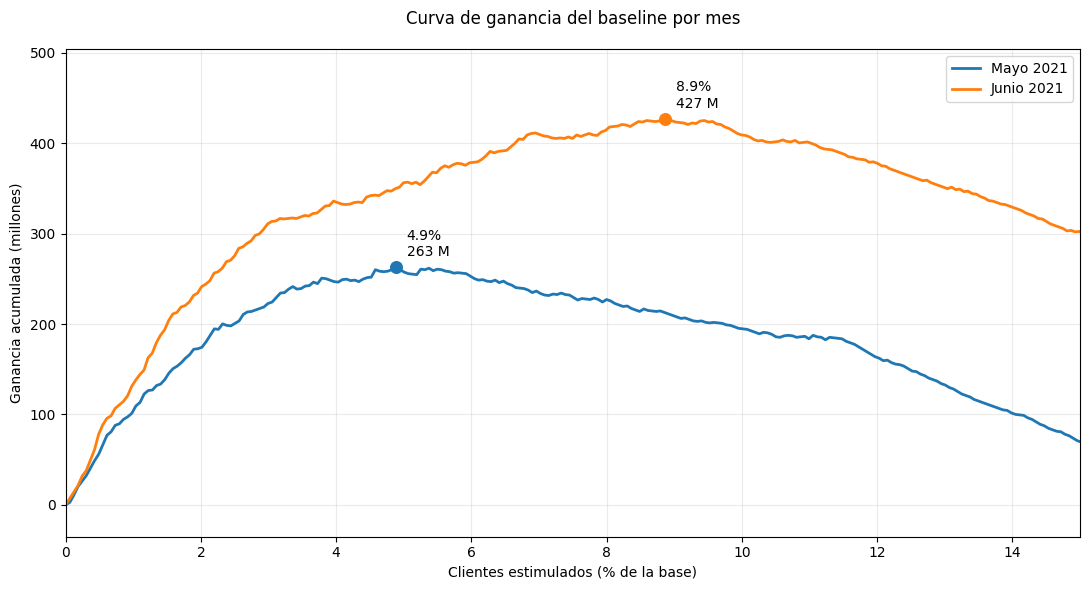

Gráfico guardado en: /Users/manuelmarasco/Desktop/dmeyf402/resultados_competenciav2/curva_ganancia_baseline.png


In [34]:
import matplotlib.pyplot as plt


def construir_curva_ganancia(
    probabilidades,
    clase_ternaria,
):
    probabilidades = np.asarray(probabilidades)
    clases = np.asarray(clase_ternaria)

    orden = np.argsort(
        -probabilidades,
        kind="mergesort",
    )

    probabilidades_ordenadas = probabilidades[orden]
    clases_ordenadas = clases[orden]

    ganancia_fila = np.where(
        clases_ordenadas == "BAJA+2",
        GANANCIA_BAJA2,
        -COSTO_ESTIMULO,
    )

    porcentaje_clientes = (
        100
        * np.arange(1, len(clases) + 1)
        / len(clases)
    )

    ganancia_acumulada = (
        np.cumsum(ganancia_fila) / 1_000_000
    )

    return {
        "porcentaje": porcentaje_clientes,
        "ganancia": ganancia_acumulada,
        "probabilidades": probabilidades_ordenadas,
    }


curvas_ganancia = {
    "Mayo 2021": construir_curva_ganancia(
        matriz_mayo.mean(axis=1),
        clase_valid_mayo,
    ),
    "Junio 2021": construir_curva_ganancia(
        probabilidad_promedio_base,
        clase_valid_base,
    ),
}

fig, ax = plt.subplots(figsize=(11, 6))

colores = {
    "Mayo 2021": "tab:blue",
    "Junio 2021": "tab:orange",
}

for nombre, curva in curvas_ganancia.items():
    indice_maximo = int(
        np.argmax(curva["ganancia"])
    )

    # Reducimos puntos solamente para dibujar más rápido.
    indices_grafico = np.unique(
        np.concatenate(
            [
                np.arange(
                    0,
                    len(curva["porcentaje"]),
                    100,
                ),
                [indice_maximo],
            ]
        )
    )

    ax.plot(
        curva["porcentaje"][indices_grafico],
        curva["ganancia"][indices_grafico],
        label=nombre,
        color=colores[nombre],
        linewidth=2,
    )

    ax.scatter(
        curva["porcentaje"][indice_maximo],
        curva["ganancia"][indice_maximo],
        color=colores[nombre],
        s=70,
        zorder=3,
    )

    ax.annotate(
        (
            f"{curva['porcentaje'][indice_maximo]:.1f}%\n"
            f"{curva['ganancia'][indice_maximo]:,.0f} M"
        ),
        (
            curva["porcentaje"][indice_maximo],
            curva["ganancia"][indice_maximo],
        ),
        xytext=(8, 8),
        textcoords="offset points",
    )

ax.set_xlim(0, 15)

ganancias_visibles = np.concatenate(
    [
        curva["ganancia"][
            curva["porcentaje"] <= 15
        ]
        for curva in curvas_ganancia.values()
    ]
)

minimo_visible = float(
    ganancias_visibles.min()
)
maximo_visible = float(
    ganancias_visibles.max()
)
rango_visible = (
    maximo_visible - minimo_visible
)

ax.set_ylim(
    min(0, minimo_visible)
    - 0.08 * rango_visible,
    maximo_visible
    + 0.18 * rango_visible,
)
ax.set_xlabel("Clientes estimulados (% de la base)")
ax.set_ylabel("Ganancia acumulada (millones)")
ax.set_title(
    "Curva de ganancia del baseline por mes",
    pad=18,
)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()

DIRECTORIO_GRAFICOS = (
    PROYECTO / "resultados_competenciav2"
)
DIRECTORIO_GRAFICOS.mkdir(
    parents=True,
    exist_ok=True,
)

ruta_grafico = (
    DIRECTORIO_GRAFICOS
    / "curva_ganancia_baseline.png"
)

fig.savefig(
    ruta_grafico,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print("Gráfico guardado en:", ruta_grafico)

In [35]:
def evaluar_regla_seleccion(
    nombre,
    origen,
    probabilidades,
    clases,
    mascara_estimulo,
):
    probabilidades = np.asarray(probabilidades)
    clases = np.asarray(clases)
    mascara_estimulo = np.asarray(
        mascara_estimulo,
        dtype=bool,
    )

    verdaderos_positivos = int(
        (
            mascara_estimulo
            & (clases == "BAJA+2")
        ).sum()
    )

    falsos_positivos = int(
        (
            mascara_estimulo
            & (clases != "BAJA+2")
        ).sum()
    )

    ganancia = (
        verdaderos_positivos * GANANCIA_BAJA2
        - falsos_positivos * COSTO_ESTIMULO
    )

    return {
        "regla": nombre,
        "origen_regla": origen,
        "clientes_estimulados": int(
            mascara_estimulo.sum()
        ),
        "pct_clientes": round(
            100
            * mascara_estimulo.mean(),
            3,
        ),
        "baja2_detectados": verdaderos_positivos,
        "no_baja2_estimulados": falsos_positivos,
        "ganancia_en_junio": ganancia,
    }


fila_mayo = comparacion_cortes.loc[
    (comparacion_cortes["mes"] == 202105)
    & (comparacion_cortes["metodo"] == "PROMEDIO")
].iloc[0]

fila_junio = comparacion_cortes.loc[
    (comparacion_cortes["mes"] == 202106)
    & (comparacion_cortes["metodo"] == "PROMEDIO")
].iloc[0]

umbral_aprendido_mayo = float(
    fila_mayo["umbral_diagnostico"]
)

pct_aprendido_mayo = float(
    fila_mayo["pct_clientes_optimos"]
)

probabilidades_junio = (
    probabilidad_promedio_base
)

cantidad_top_mayo = int(
    round(
        len(probabilidades_junio)
        * pct_aprendido_mayo
        / 100
    )
)

orden_junio = np.argsort(
    -probabilidades_junio,
    kind="mergesort",
)

mascara_top_mayo = np.zeros(
    len(probabilidades_junio),
    dtype=bool,
)
mascara_top_mayo[
    orden_junio[:cantidad_top_mayo]
] = True

cantidad_oraculo_junio = int(
    fila_junio["clientes_optimos"]
)

mascara_oraculo_junio = np.zeros(
    len(probabilidades_junio),
    dtype=bool,
)
mascara_oraculo_junio[
    orden_junio[:cantidad_oraculo_junio]
] = True

evaluacion_sobreajuste_umbral = pd.DataFrame(
    [
        evaluar_regla_seleccion(
            nombre="UMBRAL_ECONOMICO_0.025",
            origen="FIJO",
            probabilidades=probabilidades_junio,
            clases=clase_valid_base,
            mascara_estimulo=(
                probabilidades_junio >= 0.025
            ),
        ),
        evaluar_regla_seleccion(
            nombre="UMBRAL_APRENDIDO_EN_MAYO",
            origen="MAYO",
            probabilidades=probabilidades_junio,
            clases=clase_valid_base,
            mascara_estimulo=(
                probabilidades_junio
                >= umbral_aprendido_mayo
            ),
        ),
        evaluar_regla_seleccion(
            nombre="TOP_PCT_APRENDIDO_EN_MAYO",
            origen="MAYO",
            probabilidades=probabilidades_junio,
            clases=clase_valid_base,
            mascara_estimulo=mascara_top_mayo,
        ),
        evaluar_regla_seleccion(
            nombre="ORACULO_JUNIO_NO_USAR",
            origen="JUNIO",
            probabilidades=probabilidades_junio,
            clases=clase_valid_base,
            mascara_estimulo=mascara_oraculo_junio,
        ),
    ]
)

display(evaluacion_sobreajuste_umbral)

,regla,origen_regla,clientes_estimulados,pct_clientes,baja2_detectados,no_baja2_estimulados,ganancia_en_junio
0,UMBRAL_ECONOMICO_0.025,FIJO,8456,5.153,535,7921,355960000
1,UMBRAL_APRENDIDO_EN_MAYO,MAYO,6911,4.211,475,6436,332447500
2,TOP_PCT_APRENDIDO_EN_MAYO,MAYO,8009,4.880,519,7490,350652500
3,ORACULO_JUNIO_NO_USAR,JUNIO,14546,8.863,752,13794,427185000


# Variables monetarias

In [36]:
# Liberamos matrices grandes; conservamos resultados y predicciones.
del X_train_mayo
del X_valid_mayo
del y_train_mayo
gc.collect()

VARIABLES_MONETARIAS = [
    "mrentabilidad",
    "mrentabilidad_annual",
    "mcomisiones",
    "mactivos_margen",
    "mpasivos_margen",
    "mcuenta_corriente_adicional",
    "mcuenta_corriente",
    "mcaja_ahorro",
    "mcaja_ahorro_adicional",
    "mcaja_ahorro_dolares",
    "mcuentas_saldo",
    "mautoservicio",
    "mtarjeta_visa_consumo",
    "mtarjeta_master_consumo",
    "mprestamos_personales",
    "mprestamos_prendarios",
    "mprestamos_hipotecarios",
    "mplazo_fijo_dolares",
    "mplazo_fijo_pesos",
    "minversion1_pesos",
    "minversion1_dolares",
    "minversion2",
    "mpayroll",
    "mpayroll2",
    "mcuenta_debitos_automaticos",
    "mttarjeta_visa_debitos_automaticos",
    "mttarjeta_master_debitos_automaticos",
    "mpagodeservicios",
    "mpagomiscuentas",
    "mcajeros_propios_descuentos",
    "mtarjeta_visa_descuentos",
    "mtarjeta_master_descuentos",
    "mcomisiones_mantenimiento",
    "mcomisiones_otras",
    "mforex_buy",
    "mforex_sell",
    "mtransferencias_recibidas",
    "mtransferencias_emitidas",
    "mextraccion_autoservicio",
    "mcheques_depositados",
    "mcheques_emitidos",
    "mcheques_depositados_rechazados",
    "mcheques_emitidos_rechazados",
    "matm",
    "matm_other",
]

variables_monetarias_faltantes = [
    variable
    for variable in VARIABLES_MONETARIAS
    if variable not in base_modelado.columns
]

assert not variables_monetarias_faltantes, (
    "Faltan variables monetarias: "
    + ", ".join(variables_monetarias_faltantes)
)

variables_con_lag_existente = [
    variable
    for variable in VARIABLES_MONETARIAS
    if (
        f"{variable}_lag1" in base_modelado.columns
        and f"{variable}_delta1" in base_modelado.columns
    )
]

variables_con_lag_nuevo = [
    variable
    for variable in VARIABLES_MONETARIAS
    if variable not in variables_con_lag_existente
]

print(
    "Variables monetarias:",
    len(VARIABLES_MONETARIAS),
)
print(
    "Ya tenían lag y delta:",
    len(variables_con_lag_existente),
)
print(
    "Necesitan lag y delta nuevos:",
    len(variables_con_lag_nuevo),
)

Variables monetarias: 45
Ya tenían lag y delta: 9
Necesitan lag y delta nuevos: 36


In [37]:
indice_temporal = pd.MultiIndex.from_arrays(
    [
        base_modelado["numero_de_cliente"],
        base_modelado["foto_mes"],
    ]
)

assert indice_temporal.is_monotonic_increasing, (
    "La base no está ordenada por cliente y mes."
)

del indice_temporal

historia_continua = (
    base_modelado["_tiene_historia_lag1"]
    .eq(1)
)

agrupado_clientes = base_modelado.groupby(
    "numero_de_cliente",
    sort=False,
)

columnas_monetarias_nuevas = {}
features_monetarias_nuevas = []

for variable in VARIABLES_MONETARIAS:
    nombre_lag = f"{variable}_lag1"
    nombre_delta = f"{variable}_delta1"
    nombre_relativo = (
        f"{variable}_cambio_relativo_lag1"
    )

    actual = pd.to_numeric(
        base_modelado[variable],
        errors="coerce",
    ).astype("float64")

    if variable in variables_con_lag_nuevo:
        lag = pd.to_numeric(
            agrupado_clientes[variable].shift(1),
            errors="coerce",
        ).astype("float64")

        lag = lag.where(historia_continua)

        delta = (
            actual - lag
        ).where(historia_continua)

        columnas_monetarias_nuevas[
            nombre_lag
        ] = lag

        columnas_monetarias_nuevas[
            nombre_delta
        ] = delta

        features_monetarias_nuevas.extend(
            [
                nombre_lag,
                nombre_delta,
            ]
        )
    else:
        lag = pd.to_numeric(
            base_modelado[nombre_lag],
            errors="coerce",
        ).astype("float64")

    cambio_relativo = (
        (actual - lag)
        / (
            actual.abs()
            + lag.abs()
            + 1.0
        )
    ).where(historia_continua)

    columnas_monetarias_nuevas[
        nombre_relativo
    ] = cambio_relativo

    features_monetarias_nuevas.append(
        nombre_relativo
    )

colisiones = sorted(
    set(columnas_monetarias_nuevas)
    .intersection(base_modelado.columns)
)

assert not colisiones, (
    "Las nuevas features ya existían: "
    + ", ".join(colisiones)
)

nuevas_monetarias_df = pd.DataFrame(
    columnas_monetarias_nuevas,
    index=base_modelado.index,
)

base_modelado = pd.concat(
    [
        base_modelado,
        nuevas_monetarias_df,
    ],
    axis=1,
    copy=False,
)

features_candidato_monetario = (
    features_baseline
    + features_monetarias_nuevas
)

assert len(features_monetarias_nuevas) == 117
assert len(features_candidato_monetario) == 355
assert len(set(features_candidato_monetario)) == 355

infinitos_monetarios = 0

for feature in features_monetarias_nuevas:
    valores = pd.to_numeric(
        base_modelado[feature],
        errors="coerce",
    ).to_numpy(
        dtype="float64",
        na_value=np.nan,
    )

    infinitos_monetarios += int(
        np.isinf(valores).sum()
    )

fuera_de_continuidad = sum(
    int(
        base_modelado.loc[
            ~historia_continua,
            feature,
        ]
        .notna()
        .sum()
    )
    for feature in features_monetarias_nuevas
)

print(
    "Features monetarias nuevas:",
    len(features_monetarias_nuevas),
)
print(
    "Features totales del candidato:",
    len(features_candidato_monetario),
)
print(
    "Valores infinitos:",
    infinitos_monetarios,
)
print(
    "Valores fuera de continuidad:",
    fuera_de_continuidad,
)

Features monetarias nuevas: 117
Features totales del candidato: 355
Valores infinitos: 0
Valores fuera de continuidad: 0


In [38]:
# Candidato monetario:
# entrena con marzo-abril y valida en mayo.

X_train_monetario_mayo = base_modelado.loc[
    base_modelado["foto_mes"].isin([202103, 202104]),
    features_candidato_monetario,
]

y_train_monetario_mayo = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin([202103, 202104]),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_monetario_mayo = base_modelado.loc[
    base_modelado["foto_mes"].eq(202105),
    features_candidato_monetario,
]

y_valid_monetario_mayo = (
    base_modelado.loc[
        base_modelado["foto_mes"].eq(202105),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

clase_valid_monetario_mayo = (
    base_modelado.loc[
        base_modelado["foto_mes"].eq(202105),
        "clase_ternaria",
    ]
    .astype("object")
    .to_numpy()
)

print("Entrenamiento:", X_train_monetario_mayo.shape)
print("Validación:", X_valid_monetario_mayo.shape)
print("Features:", len(features_candidato_monetario))

resultado_monetario_mayo = entrenar_ensemble_lightgbm(
    X_train=X_train_monetario_mayo,
    y_train=y_train_monetario_mayo,
    X_valid=X_valid_monetario_mayo,
    y_valid=y_valid_monetario_mayo,
    clase_valid=clase_valid_monetario_mayo,
    etiqueta="MONETARIO_202105",
)

display(
    resultado_monetario_mayo["metricas_ensemble"]
)

Entrenamiento: (326184, 355)
Validación: (163768, 355)
Features: 355
MONETARIO_202105 | Semilla 100129 | Ganancia 265,347,500 | AUC 0.8946
MONETARIO_202105 | Semilla 100183 | Ganancia 265,925,000 | AUC 0.8955
MONETARIO_202105 | Semilla 100151 | Ganancia 263,175,000 | AUC 0.8948
MONETARIO_202105 | Semilla 500041 | Ganancia 257,125,000 | AUC 0.8954
MONETARIO_202105 | Semilla 900007 | Ganancia 259,352,500 | AUC 0.8944


,validacion,metodo,ganancia,auc,clientes_estimulados
0,MONETARIO_202105,PROMEDIO,262432500.0,0.895762,9537
1,MONETARIO_202105,MEDIANA,263532500.0,0.895476,9457


Es una mejora provisional:
- Promedio: de 254,38 M a 262,43 M → +8,06 M (+3,17%).
- Mediana: de 251,76 M a 263,53 M → +11,77 M (+4,68%).
- El AUC mejoró muy poco; lo importante es que aumentó la ganancia.
Todavía no aceptamos las features: falta comprobar junio.

In [39]:
# Liberamos las matrices grandes de mayo.
del X_train_monetario_mayo
del X_valid_monetario_mayo
del y_train_monetario_mayo
del y_valid_monetario_mayo
del clase_valid_monetario_mayo
gc.collect()

# Candidato monetario:
# entrena con marzo-mayo y valida en junio.

X_train_monetario_junio = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104, 202105]
    ),
    features_candidato_monetario,
]

y_train_monetario_junio = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104, 202105]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_monetario_junio = base_modelado.loc[
    base_modelado["foto_mes"].eq(202106),
    features_candidato_monetario,
]

y_valid_monetario_junio = (
    base_modelado.loc[
        base_modelado["foto_mes"].eq(202106),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

clase_valid_monetario_junio = (
    base_modelado.loc[
        base_modelado["foto_mes"].eq(202106),
        "clase_ternaria",
    ]
    .astype("object")
    .to_numpy()
)

print("Entrenamiento:", X_train_monetario_junio.shape)
print("Validación:", X_valid_monetario_junio.shape)
print("Features:", len(features_candidato_monetario))

resultado_monetario_junio = entrenar_ensemble_lightgbm(
    X_train=X_train_monetario_junio,
    y_train=y_train_monetario_junio,
    X_valid=X_valid_monetario_junio,
    y_valid=y_valid_monetario_junio,
    clase_valid=clase_valid_monetario_junio,
    etiqueta="MONETARIO_202106",
)

display(
    resultado_monetario_junio["metricas_ensemble"]
)

Entrenamiento: (489952, 355)
Validación: (164114, 355)
Features: 355
MONETARIO_202106 | Semilla 100129 | Ganancia 364,457,500 | AUC 0.9041
MONETARIO_202106 | Semilla 100183 | Ganancia 366,932,500 | AUC 0.9040
MONETARIO_202106 | Semilla 100151 | Ganancia 363,000,000 | AUC 0.9046
MONETARIO_202106 | Semilla 500041 | Ganancia 371,195,000 | AUC 0.9041
MONETARIO_202106 | Semilla 900007 | Ganancia 360,195,000 | AUC 0.9041


,validacion,metodo,ganancia,auc,clientes_estimulados
0,MONETARIO_202106,PROMEDIO,367922500.0,0.905059,8381
1,MONETARIO_202106,MEDIANA,362395000.0,0.904776,8302


,mes,metodo,auc,ganancia_umbral_0025,ganancia_optima_diagnostica,clientes_optimos,pct_clientes_optimos,baja2_encontrados,pct_techo_alcanzado
0,202105,BASELINE,0.895017,254375000.0,263120000.0,7992,4.880,439,28.20
1,202105,MONETARIO,0.895762,262432500.0,269225000.0,8890,5.428,467,28.85
2,202106,BASELINE,0.905267,355960000.0,427185000.0,14546,8.863,752,36.28
3,202106,MONETARIO,0.905059,367922500.0,415057500.0,14227,8.669,733,35.25


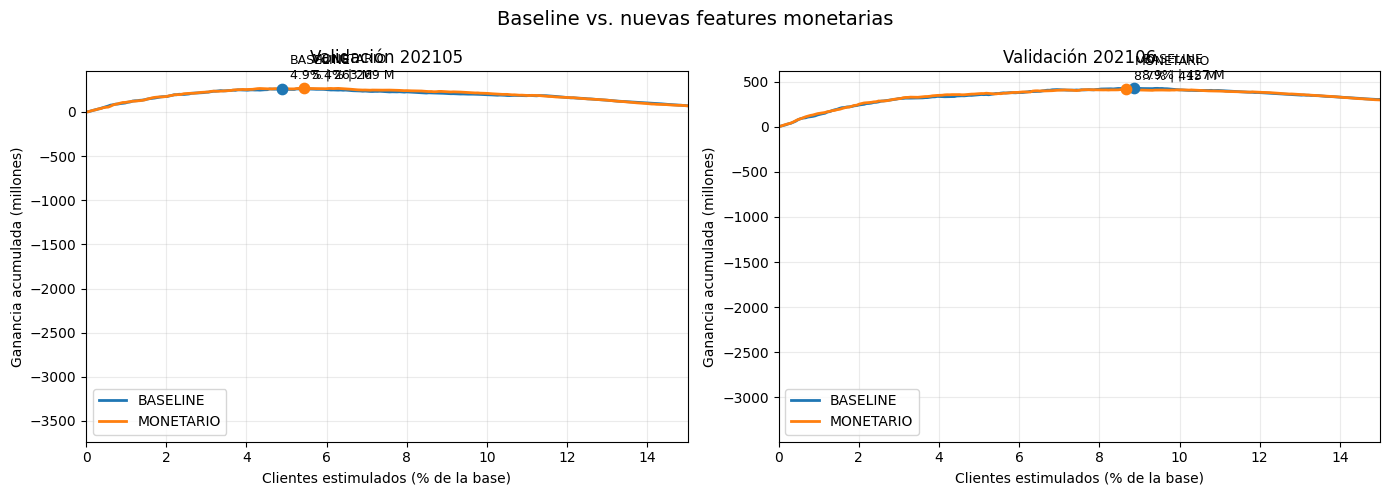

Gráfico guardado en: /Users/manuelmarasco/Desktop/dmeyf402/resultados_competenciav2/baseline_vs_features_monetarias.png


In [40]:
# Liberamos matrices grandes de junio.
for nombre_variable in [
    "X_train_monetario_junio",
    "X_valid_monetario_junio",
    "y_train_monetario_junio",
    "y_valid_monetario_junio",
    "clase_valid_monetario_junio",
]:
    globals().pop(nombre_variable, None)

gc.collect()

# Predicciones promedio de los cinco modelos.
prob_monetario_mayo = (
    resultado_monetario_mayo["matriz"].mean(axis=1)
)

prob_monetario_junio = (
    resultado_monetario_junio["matriz"].mean(axis=1)
)

comparaciones_modelos = [
    (
        202105,
        "BASELINE",
        y_valid_mayo,
        clase_valid_mayo,
        matriz_mayo.mean(axis=1),
    ),
    (
        202105,
        "MONETARIO",
        y_valid_mayo,
        clase_valid_mayo,
        prob_monetario_mayo,
    ),
    (
        202106,
        "BASELINE",
        y_valid_base,
        clase_valid_base,
        probabilidad_promedio_base,
    ),
    (
        202106,
        "MONETARIO",
        y_valid_base,
        clase_valid_base,
        prob_monetario_junio,
    ),
]

filas_comparacion_monetaria = []

for (
    mes,
    modelo,
    y_mes,
    clase_mes,
    probabilidades,
) in comparaciones_modelos:

    resumen = resumir_corte_ganancia(
        mes=mes,
        metodo=modelo,
        y_binaria=y_mes,
        clase_ternaria=clase_mes,
        probabilidades=probabilidades,
    )

    techo_ganancia = (
        int(np.sum(y_mes))
        * GANANCIA_BAJA2
    )

    resumen["auc"] = roc_auc_score(
        y_mes,
        probabilidades,
    )

    resumen["pct_techo_alcanzado"] = round(
        100
        * resumen["ganancia_optima_diagnostica"]
        / techo_ganancia,
        2,
    )

    filas_comparacion_monetaria.append(resumen)

comparacion_monetaria = pd.DataFrame(
    filas_comparacion_monetaria
)

display(
    comparacion_monetaria[
        [
            "mes",
            "metodo",
            "auc",
            "ganancia_umbral_0025",
            "ganancia_optima_diagnostica",
            "clientes_optimos",
            "pct_clientes_optimos",
            "baja2_encontrados",
            "pct_techo_alcanzado",
        ]
    ]
)

# Curvas de ganancia por mes.
fig, ejes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

for eje, mes in zip(
    ejes,
    [202105, 202106],
):
    subconjunto = [
        elemento
        for elemento in comparaciones_modelos
        if elemento[0] == mes
    ]

    for (
        _,
        modelo,
        _,
        clase_mes,
        probabilidades,
    ) in subconjunto:

        curva = construir_curva_ganancia(
            probabilidades,
            clase_mes,
        )

        indice_maximo = int(
            np.argmax(curva["ganancia"])
        )

        indices_grafico = np.unique(
            np.concatenate(
                [
                    np.arange(
                        0,
                        len(curva["porcentaje"]),
                        100,
                    ),
                    [indice_maximo],
                ]
            )
        )

        eje.plot(
            curva["porcentaje"][indices_grafico],
            curva["ganancia"][indices_grafico],
            linewidth=2,
            label=modelo,
        )

        eje.scatter(
            curva["porcentaje"][indice_maximo],
            curva["ganancia"][indice_maximo],
            s=55,
            zorder=3,
        )

        eje.annotate(
            (
                f"{modelo}\n"
                f"{curva['porcentaje'][indice_maximo]:.1f}% | "
                f"{curva['ganancia'][indice_maximo]:,.0f} M"
            ),
            (
                curva["porcentaje"][indice_maximo],
                curva["ganancia"][indice_maximo],
            ),
            xytext=(6, 7),
            textcoords="offset points",
            fontsize=9,
        )

    eje.set_xlim(0, 15)
    eje.set_title(f"Validación {mes}")
    eje.set_xlabel(
        "Clientes estimulados (% de la base)"
    )
    eje.set_ylabel(
        "Ganancia acumulada (millones)"
    )
    eje.grid(alpha=0.25)
    eje.legend()

fig.suptitle(
    "Baseline vs. nuevas features monetarias",
    fontsize=14,
)

plt.tight_layout()

ruta_grafico_monetario = (
    DIRECTORIO_GRAFICOS
    / "baseline_vs_features_monetarias.png"
)

fig.savefig(
    ruta_grafico_monetario,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Gráfico guardado en:",
    ruta_grafico_monetario,
)

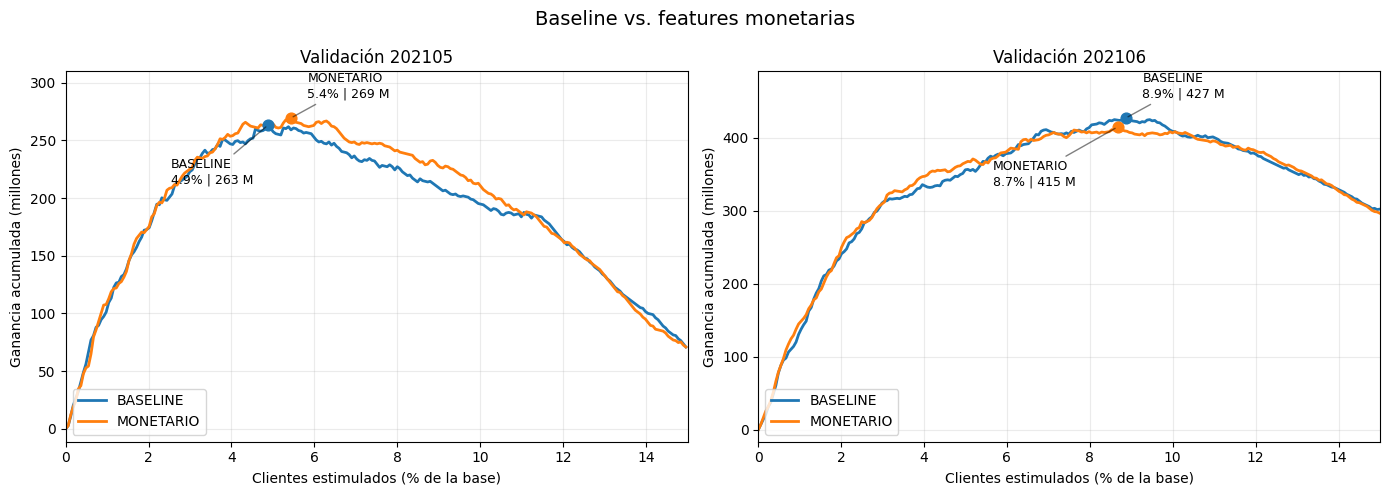

In [41]:
fig, ejes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

colores_modelos = {
    "BASELINE": "tab:blue",
    "MONETARIO": "tab:orange",
}

desplazamientos = {
    (202105, "BASELINE"): (-70, -42),
    (202105, "MONETARIO"): (12, 15),
    (202106, "BASELINE"): (12, 15),
    (202106, "MONETARIO"): (-90, -42),
}

for eje, mes in zip(ejes, [202105, 202106]):
    ganancias_visibles = []

    for (
        _,
        modelo,
        _,
        clase_mes,
        probabilidades,
    ) in [
        elemento
        for elemento in comparaciones_modelos
        if elemento[0] == mes
    ]:
        curva = construir_curva_ganancia(
            probabilidades,
            clase_mes,
        )

        mascara_visible = (
            curva["porcentaje"] <= 15
        )

        porcentajes_visibles = (
            curva["porcentaje"][mascara_visible]
        )

        ganancias_modelo_visibles = (
            curva["ganancia"][mascara_visible]
        )

        ganancias_visibles.append(
            ganancias_modelo_visibles
        )

        indices_reducidos = np.arange(
            0,
            len(porcentajes_visibles),
            100,
        )

        eje.plot(
            porcentajes_visibles[indices_reducidos],
            ganancias_modelo_visibles[indices_reducidos],
            linewidth=2,
            color=colores_modelos[modelo],
            label=modelo,
        )

        indice_maximo = int(
            np.argmax(curva["ganancia"])
        )

        x_maximo = float(
            curva["porcentaje"][indice_maximo]
        )

        y_maximo = float(
            curva["ganancia"][indice_maximo]
        )

        eje.scatter(
            x_maximo,
            y_maximo,
            color=colores_modelos[modelo],
            s=60,
            zorder=3,
        )

        eje.annotate(
            (
                f"{modelo}\n"
                f"{x_maximo:.1f}% | {y_maximo:,.0f} M"
            ),
            (x_maximo, y_maximo),
            xytext=desplazamientos[(mes, modelo)],
            textcoords="offset points",
            fontsize=9,
            arrowprops={
                "arrowstyle": "-",
                "alpha": 0.5,
            },
        )

    ganancias_visibles = np.concatenate(
        ganancias_visibles
    )

    minimo_visible = min(
        0,
        float(ganancias_visibles.min()),
    )

    maximo_visible = float(
        ganancias_visibles.max()
    )

    margen = (
        maximo_visible - minimo_visible
    ) * 0.15

    eje.set_xlim(0, 15)
    eje.set_ylim(
        minimo_visible - margen * 0.25,
        maximo_visible + margen,
    )

    eje.set_title(f"Validación {mes}")
    eje.set_xlabel(
        "Clientes estimulados (% de la base)"
    )
    eje.set_ylabel(
        "Ganancia acumulada (millones)"
    )
    eje.grid(alpha=0.25)
    eje.legend(loc="lower left")

fig.suptitle(
    "Baseline vs. features monetarias",
    fontsize=14,
)

plt.tight_layout()

fig.savefig(
    ruta_grafico_monetario,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [42]:
features_lag_delta_monetarias = []

for variable in variables_con_lag_nuevo:
    features_lag_delta_monetarias.extend(
        [
            f"{variable}_lag1",
            f"{variable}_delta1",
        ]
    )

features_cambios_relativos_monetarios = [
    f"{variable}_cambio_relativo_lag1"
    for variable in VARIABLES_MONETARIAS
]

features_candidato_lag_delta_monetario = (
    features_baseline
    + features_lag_delta_monetarias
)

features_candidato_cambio_relativo = (
    features_baseline
    + features_cambios_relativos_monetarios
)

assert len(features_lag_delta_monetarias) == 72
assert len(features_cambios_relativos_monetarios) == 45

print(
    "Nuevos lag/delta monetarios:",
    len(features_lag_delta_monetarias),
)
print(
    "Nuevos cambios relativos:",
    len(features_cambios_relativos_monetarios),
)
print(
    "Candidato lag/delta:",
    len(features_candidato_lag_delta_monetario),
)
print(
    "Candidato cambios relativos:",
    len(features_candidato_cambio_relativo),
)

Nuevos lag/delta monetarios: 72
Nuevos cambios relativos: 45
Candidato lag/delta: 310
Candidato cambios relativos: 283


In [43]:
X_train_lag_delta_mayo = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104]
    ),
    features_candidato_lag_delta_monetario,
]

y_train_lag_delta_mayo = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_lag_delta_mayo = base_modelado.loc[
    base_modelado["foto_mes"].eq(202105),
    features_candidato_lag_delta_monetario,
]

print(
    "Entrenamiento:",
    X_train_lag_delta_mayo.shape,
)
print(
    "Validación:",
    X_valid_lag_delta_mayo.shape,
)

resultado_lag_delta_mayo = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_lag_delta_mayo,
        y_train=y_train_lag_delta_mayo,
        X_valid=X_valid_lag_delta_mayo,
        y_valid=y_valid_mayo,
        clase_valid=clase_valid_mayo,
        etiqueta="LAG_DELTA_202105",
    )
)

display(
    resultado_lag_delta_mayo[
        "metricas_ensemble"
    ]
)

Entrenamiento: (326184, 310)
Validación: (163768, 310)
LAG_DELTA_202105 | Semilla 100129 | Ganancia 257,427,500 | AUC 0.8966
LAG_DELTA_202105 | Semilla 100183 | Ganancia 266,860,000 | AUC 0.8944
LAG_DELTA_202105 | Semilla 100151 | Ganancia 261,195,000 | AUC 0.8956
LAG_DELTA_202105 | Semilla 500041 | Ganancia 264,220,000 | AUC 0.8941
LAG_DELTA_202105 | Semilla 900007 | Ganancia 258,115,000 | AUC 0.8955


,validacion,metodo,ganancia,auc,clientes_estimulados
0,LAG_DELTA_202105,PROMEDIO,264550000.0,0.896075,9580
1,LAG_DELTA_202105,MEDIANA,265677500.0,0.896025,9499


In [44]:
# Liberamos matrices grandes de mayo.
for nombre_variable in [
    "X_train_lag_delta_mayo",
    "X_valid_lag_delta_mayo",
    "y_train_lag_delta_mayo",
]:
    globals().pop(nombre_variable, None)

gc.collect()

X_train_lag_delta_junio = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104, 202105]
    ),
    features_candidato_lag_delta_monetario,
]

y_train_lag_delta_junio = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104, 202105]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_lag_delta_junio = base_modelado.loc[
    base_modelado["foto_mes"].eq(202106),
    features_candidato_lag_delta_monetario,
]

print(
    "Entrenamiento:",
    X_train_lag_delta_junio.shape,
)
print(
    "Validación:",
    X_valid_lag_delta_junio.shape,
)

resultado_lag_delta_junio = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_lag_delta_junio,
        y_train=y_train_lag_delta_junio,
        X_valid=X_valid_lag_delta_junio,
        y_valid=y_valid_base,
        clase_valid=clase_valid_base,
        etiqueta="LAG_DELTA_202106",
    )
)

display(
    resultado_lag_delta_junio[
        "metricas_ensemble"
    ]
)

Entrenamiento: (489952, 310)
Validación: (164114, 310)
LAG_DELTA_202106 | Semilla 100129 | Ganancia 353,017,500 | AUC 0.9028
LAG_DELTA_202106 | Semilla 100183 | Ganancia 370,617,500 | AUC 0.9033
LAG_DELTA_202106 | Semilla 100151 | Ganancia 372,845,000 | AUC 0.9041
LAG_DELTA_202106 | Semilla 500041 | Ganancia 366,520,000 | AUC 0.9036
LAG_DELTA_202106 | Semilla 900007 | Ganancia 367,070,000 | AUC 0.9041


,validacion,metodo,ganancia,auc,clientes_estimulados
0,LAG_DELTA_202106,PROMEDIO,372130000.0,0.904390,8468
1,LAG_DELTA_202106,MEDIANA,369765000.0,0.904379,8394


In [45]:
# Liberamos las matrices grandes de junio.
for nombre_variable in [
    "X_train_lag_delta_junio",
    "X_valid_lag_delta_junio",
    "y_train_lag_delta_junio",
]:
    globals().pop(nombre_variable, None)

gc.collect()

prob_lag_delta_mayo = (
    resultado_lag_delta_mayo["matriz"].mean(axis=1)
)

prob_lag_delta_junio = (
    resultado_lag_delta_junio["matriz"].mean(axis=1)
)

modelos_comparados = [
    (
        202105,
        "BASELINE",
        y_valid_mayo,
        clase_valid_mayo,
        matriz_mayo.mean(axis=1),
    ),
    (
        202105,
        "117_MONETARIAS",
        y_valid_mayo,
        clase_valid_mayo,
        prob_monetario_mayo,
    ),
    (
        202105,
        "72_LAG_DELTA",
        y_valid_mayo,
        clase_valid_mayo,
        prob_lag_delta_mayo,
    ),
    (
        202106,
        "BASELINE",
        y_valid_base,
        clase_valid_base,
        probabilidad_promedio_base,
    ),
    (
        202106,
        "117_MONETARIAS",
        y_valid_base,
        clase_valid_base,
        prob_monetario_junio,
    ),
    (
        202106,
        "72_LAG_DELTA",
        y_valid_base,
        clase_valid_base,
        prob_lag_delta_junio,
    ),
]

filas_comparacion = []

for (
    mes,
    modelo,
    y_mes,
    clase_mes,
    probabilidades,
) in modelos_comparados:

    resumen = resumir_corte_ganancia(
        mes=mes,
        metodo=modelo,
        y_binaria=y_mes,
        clase_ternaria=clase_mes,
        probabilidades=probabilidades,
    )

    filas_comparacion.append(
        {
            "mes": mes,
            "modelo": modelo,
            "auc": roc_auc_score(
                y_mes,
                probabilidades,
            ),
            "ganancia_umbral_0025": resumen[
                "ganancia_umbral_0025"
            ],
            "ganancia_maxima_diagnostica": resumen[
                "ganancia_optima_diagnostica"
            ],
            "pct_clientes_en_maximo": resumen[
                "pct_clientes_optimos"
            ],
        }
    )

comparacion_tres_modelos = pd.DataFrame(
    filas_comparacion
)

comparacion_tres_modelos[
    "mejora_fija_vs_baseline"
] = (
    comparacion_tres_modelos[
        "ganancia_umbral_0025"
    ]
    - comparacion_tres_modelos.groupby(
        "mes"
    )[
        "ganancia_umbral_0025"
    ].transform("first")
)

comparacion_tres_modelos[
    "mejora_maxima_vs_baseline"
] = (
    comparacion_tres_modelos[
        "ganancia_maxima_diagnostica"
    ]
    - comparacion_tres_modelos.groupby(
        "mes"
    )[
        "ganancia_maxima_diagnostica"
    ].transform("first")
)

display(comparacion_tres_modelos)

,mes,modelo,auc,ganancia_umbral_0025,ganancia_maxima_diagnostica,pct_clientes_en_maximo,mejora_fija_vs_baseline,mejora_maxima_vs_baseline
0,202105,BASELINE,0.895017,254375000.0,263120000.0,4.880,0.0,0.0
1,202105,117_MONETARIAS,0.895762,262432500.0,269225000.0,5.428,8057500.0,6105000.0
2,202105,72_LAG_DELTA,0.896075,264550000.0,272497500.0,5.307,10175000.0,9377500.0
3,202106,BASELINE,0.905267,355960000.0,427185000.0,8.863,0.0,0.0
4,202106,117_MONETARIAS,0.905059,367922500.0,415057500.0,8.669,11962500.0,-12127500.0
5,202106,72_LAG_DELTA,0.904390,372130000.0,413050000.0,9.420,16170000.0,-14135000.0


In [46]:
predicciones_transferencia = {
    "BASELINE": {
        "mayo": matriz_mayo.mean(axis=1),
        "junio": probabilidad_promedio_base,
    },
    "117_MONETARIAS": {
        "mayo": prob_monetario_mayo,
        "junio": prob_monetario_junio,
    },
    "72_LAG_DELTA": {
        "mayo": prob_lag_delta_mayo,
        "junio": prob_lag_delta_junio,
    },
}

filas_transferencia = []

for modelo, predicciones in (
    predicciones_transferencia.items()
):
    curva_mayo_modelo = construir_curva_ganancia(
        predicciones["mayo"],
        clase_valid_mayo,
    )

    indice_optimo_mayo = int(
        np.argmax(
            curva_mayo_modelo["ganancia"]
        )
    )

    pct_aprendido_mayo = float(
        curva_mayo_modelo["porcentaje"][
            indice_optimo_mayo
        ]
    )

    cantidad_junio = int(
        round(
            len(predicciones["junio"])
            * pct_aprendido_mayo
            / 100
        )
    )

    orden_junio = np.argsort(
        -predicciones["junio"],
        kind="mergesort",
    )

    mascara_junio = np.zeros(
        len(predicciones["junio"]),
        dtype=bool,
    )

    mascara_junio[
        orden_junio[:cantidad_junio]
    ] = True

    baja2_detectados = int(
        (
            mascara_junio
            & (clase_valid_base == "BAJA+2")
        ).sum()
    )

    no_baja2_estimulados = int(
        cantidad_junio - baja2_detectados
    )

    ganancia_transferida = (
        baja2_detectados * GANANCIA_BAJA2
        - no_baja2_estimulados
        * COSTO_ESTIMULO
    )

    ganancia_umbral_fijo = (
        evaluar_predicciones(
            y_binaria=y_valid_base,
            clase_ternaria=clase_valid_base,
            probabilidades=predicciones["junio"],
        )["ganancia"]
    )

    filas_transferencia.append(
        {
            "modelo": modelo,
            "pct_aprendido_en_mayo": round(
                pct_aprendido_mayo,
                3,
            ),
            "clientes_estimulados_en_junio": (
                cantidad_junio
            ),
            "baja2_detectados_en_junio": (
                baja2_detectados
            ),
            "no_baja2_estimulados": (
                no_baja2_estimulados
            ),
            "ganancia_top_pct_mayo_en_junio": (
                ganancia_transferida
            ),
            "ganancia_umbral_0025_en_junio": (
                ganancia_umbral_fijo
            ),
        }
    )

comparacion_transferencia = pd.DataFrame(
    filas_transferencia
)

ganancia_referencia_transferida = float(
    comparacion_transferencia.loc[
        comparacion_transferencia[
            "modelo"
        ].eq("BASELINE"),
        "ganancia_top_pct_mayo_en_junio",
    ].iloc[0]
)

comparacion_transferencia[
    "mejora_transferida_vs_baseline"
] = (
    comparacion_transferencia[
        "ganancia_top_pct_mayo_en_junio"
    ]
    - ganancia_referencia_transferida
)

display(comparacion_transferencia)

,modelo,pct_aprendido_en_mayo,clientes_estimulados_en_junio,baja2_detectados_en_junio,no_baja2_estimulados,ganancia_top_pct_mayo_en_junio,ganancia_umbral_0025_en_junio,mejora_transferida_vs_baseline
0,BASELINE,4.880,8009,519,7490,350652500,355960000.0,0.0
1,117_MONETARIAS,5.428,8909,554,8355,364402500,367922500.0,13750000.0
2,72_LAG_DELTA,5.307,8709,557,8152,373202500,372130000.0,22550000.0


In [47]:
# Nueva referencia aceptada provisionalmente.
features_referencia_actual = (
    features_candidato_lag_delta_monetario.copy()
)

PARES_CANTIDAD_MONTO = {
    "debito": (
        "ctarjeta_debito_transacciones",
        "mautoservicio",
    ),
    "visa": (
        "ctarjeta_visa_transacciones",
        "mtarjeta_visa_consumo",
    ),
    "master": (
        "ctarjeta_master_transacciones",
        "mtarjeta_master_consumo",
    ),
    "payroll": (
        "cpayroll_trx",
        "mpayroll",
    ),
    "debitos_cuenta": (
        "ccuenta_debitos_automaticos",
        "mcuenta_debitos_automaticos",
    ),
    "debitos_visa": (
        "ctarjeta_visa_debitos_automaticos",
        "mttarjeta_visa_debitos_automaticos",
    ),
    "debitos_master": (
        "ctarjeta_master_debitos_automaticos",
        "mttarjeta_master_debitos_automaticos",
    ),
    "pago_servicios": (
        "cpagodeservicios",
        "mpagodeservicios",
    ),
    "pago_mis_cuentas": (
        "cpagomiscuentas",
        "mpagomiscuentas",
    ),
    "descuentos_cajeros": (
        "ccajeros_propios_descuentos",
        "mcajeros_propios_descuentos",
    ),
    "descuentos_visa": (
        "ctarjeta_visa_descuentos",
        "mtarjeta_visa_descuentos",
    ),
    "descuentos_master": (
        "ctarjeta_master_descuentos",
        "mtarjeta_master_descuentos",
    ),
    "comisiones_mantenimiento": (
        "ccomisiones_mantenimiento",
        "mcomisiones_mantenimiento",
    ),
    "comisiones_otras": (
        "ccomisiones_otras",
        "mcomisiones_otras",
    ),
    "forex_buy": (
        "cforex_buy",
        "mforex_buy",
    ),
    "forex_sell": (
        "cforex_sell",
        "mforex_sell",
    ),
    "transferencias_recibidas": (
        "ctransferencias_recibidas",
        "mtransferencias_recibidas",
    ),
    "transferencias_emitidas": (
        "ctransferencias_emitidas",
        "mtransferencias_emitidas",
    ),
    "extraccion_autoservicio": (
        "cextraccion_autoservicio",
        "mextraccion_autoservicio",
    ),
    "cheques_depositados": (
        "ccheques_depositados",
        "mcheques_depositados",
    ),
    "cheques_emitidos": (
        "ccheques_emitidos",
        "mcheques_emitidos",
    ),
    "atm_propio": (
        "catm_trx",
        "matm",
    ),
    "atm_ajeno": (
        "catm_trx_other",
        "matm_other",
    ),
}

columnas_requeridas = {
    columna
    for par in PARES_CANTIDAD_MONTO.values()
    for columna in par
}

columnas_faltantes = sorted(
    columnas_requeridas
    - set(base_modelado.columns)
)

assert not columnas_faltantes, (
    "Faltan columnas: "
    + ", ".join(columnas_faltantes)
)

columnas_tickets = {}

for nombre, (
    columna_cantidad,
    columna_monto,
) in PARES_CANTIDAD_MONTO.items():

    cantidad = pd.to_numeric(
        base_modelado[columna_cantidad],
        errors="coerce",
    ).astype("float64")

    monto = pd.to_numeric(
        base_modelado[columna_monto],
        errors="coerce",
    ).astype("float64")

    columnas_tickets[
        f"ticket_promedio_{nombre}"
    ] = (
        monto / cantidad
    ).where(cantidad > 0)

tickets_df = pd.DataFrame(
    columnas_tickets,
    index=base_modelado.index,
)

features_tickets_cm = list(
    columnas_tickets.keys()
)

colisiones = sorted(
    set(features_tickets_cm)
    .intersection(base_modelado.columns)
)

assert not colisiones, (
    "Las features ya existían: "
    + ", ".join(colisiones)
)

base_modelado = pd.concat(
    [base_modelado, tickets_df],
    axis=1,
    copy=False,
)

features_candidato_tickets = (
    features_referencia_actual
    + features_tickets_cm
)

infinitos_tickets = sum(
    int(
        np.isinf(
            pd.to_numeric(
                base_modelado[feature],
                errors="coerce",
            ).to_numpy(
                dtype="float64",
                na_value=np.nan,
            )
        ).sum()
    )
    for feature in features_tickets_cm
)

print(
    "Features de referencia:",
    len(features_referencia_actual),
)
print(
    "Tickets promedio nuevos:",
    len(features_tickets_cm),
)
print(
    "Features del candidato:",
    len(features_candidato_tickets),
)
print(
    "Valores infinitos:",
    infinitos_tickets,
)

Features de referencia: 310
Tickets promedio nuevos: 23
Features del candidato: 333
Valores infinitos: 0


In [48]:
X_train_tickets_mayo = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104]
    ),
    features_candidato_tickets,
]

y_train_tickets_mayo = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_tickets_mayo = base_modelado.loc[
    base_modelado["foto_mes"].eq(202105),
    features_candidato_tickets,
]

print(
    "Entrenamiento:",
    X_train_tickets_mayo.shape,
)
print(
    "Validación:",
    X_valid_tickets_mayo.shape,
)

resultado_tickets_mayo = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_tickets_mayo,
        y_train=y_train_tickets_mayo,
        X_valid=X_valid_tickets_mayo,
        y_valid=y_valid_mayo,
        clase_valid=clase_valid_mayo,
        etiqueta="TICKETS_202105",
    )
)

display(
    resultado_tickets_mayo[
        "metricas_ensemble"
    ]
)

Entrenamiento: (326184, 333)
Validación: (163768, 333)
TICKETS_202105 | Semilla 100129 | Ganancia 258,417,500 | AUC 0.8951
TICKETS_202105 | Semilla 100183 | Ganancia 259,215,000 | AUC 0.8964
TICKETS_202105 | Semilla 100151 | Ganancia 263,917,500 | AUC 0.8948
TICKETS_202105 | Semilla 500041 | Ganancia 260,947,500 | AUC 0.8946
TICKETS_202105 | Semilla 900007 | Ganancia 265,265,000 | AUC 0.8958


,validacion,metodo,ganancia,auc,clientes_estimulados
0,TICKETS_202105,PROMEDIO,264935000.0,0.896067,9566
1,TICKETS_202105,MEDIANA,263175000.0,0.895842,9510


En mayo, los tickets promedio quedaron prácticamente empatados con la referencia:
- Referencia de 310 features: 264,55 M, AUC 0.896075.
- Con tickets, 333 features: 264,94 M, AUC 0.896067.
- Diferencia: apenas +0,39 M y AUC sin cambio real.
No alcanza para aceptarlos ni descartarlos. Probamos junio.
Debajo de esa salida, ejecutá:

In [49]:
# Liberamos las matrices grandes de mayo.
for nombre_variable in [
    "X_train_tickets_mayo",
    "X_valid_tickets_mayo",
    "y_train_tickets_mayo",
]:
    globals().pop(nombre_variable, None)

gc.collect()

X_train_tickets_junio = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104, 202105]
    ),
    features_candidato_tickets,
]

y_train_tickets_junio = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104, 202105]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_tickets_junio = base_modelado.loc[
    base_modelado["foto_mes"].eq(202106),
    features_candidato_tickets,
]

print(
    "Entrenamiento:",
    X_train_tickets_junio.shape,
)
print(
    "Validación:",
    X_valid_tickets_junio.shape,
)

resultado_tickets_junio = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_tickets_junio,
        y_train=y_train_tickets_junio,
        X_valid=X_valid_tickets_junio,
        y_valid=y_valid_base,
        clase_valid=clase_valid_base,
        etiqueta="TICKETS_202106",
    )
)

display(
    resultado_tickets_junio[
        "metricas_ensemble"
    ]
)

Entrenamiento: (489952, 333)
Validación: (164114, 333)
TICKETS_202106 | Semilla 100129 | Ganancia 365,475,000 | AUC 0.9031
TICKETS_202106 | Semilla 100183 | Ganancia 364,457,500 | AUC 0.9037
TICKETS_202106 | Semilla 100151 | Ganancia 375,870,000 | AUC 0.9037
TICKETS_202106 | Semilla 500041 | Ganancia 363,907,500 | AUC 0.9042
TICKETS_202106 | Semilla 900007 | Ganancia 356,042,500 | AUC 0.9034


,validacion,metodo,ganancia,auc,clientes_estimulados
0,TICKETS_202106,PROMEDIO,365557500.0,0.904539,8507
1,TICKETS_202106,MEDIANA,364100000.0,0.904659,8440


En junio, los tickets empeoran la ganancia:
- Referencia de 310 features: 372,13 M.
- Con 23 tickets: 365,56 M.
- Diferencia: −6,57 M.
- El AUC sube apenas 0.00015, una diferencia demasiado pequeña.
Antes de descartarlos, hacemos la misma prueba temporal mayo → junio.

In [50]:
# Liberamos matrices grandes.
for nombre_variable in [
    "X_train_tickets_junio",
    "X_valid_tickets_junio",
    "y_train_tickets_junio",
]:
    globals().pop(nombre_variable, None)

gc.collect()

prob_tickets_mayo = (
    resultado_tickets_mayo["matriz"].mean(axis=1)
)

prob_tickets_junio = (
    resultado_tickets_junio["matriz"].mean(axis=1)
)

def transferir_pct_mayo_a_junio(
    nombre_modelo,
    probabilidades_mayo,
    probabilidades_junio,
):
    curva_mayo = construir_curva_ganancia(
        probabilidades_mayo,
        clase_valid_mayo,
    )

    indice_maximo_mayo = int(
        np.argmax(curva_mayo["ganancia"])
    )

    pct_mayo = float(
        curva_mayo["porcentaje"][
            indice_maximo_mayo
        ]
    )

    cantidad_junio = int(
        round(
            len(probabilidades_junio)
            * pct_mayo
            / 100
        )
    )

    orden_junio = np.argsort(
        -probabilidades_junio,
        kind="mergesort",
    )

    seleccionados = orden_junio[
        :cantidad_junio
    ]

    clases_seleccionadas = (
        clase_valid_base[seleccionados]
    )

    baja2_detectados = int(
        (
            clases_seleccionadas
            == "BAJA+2"
        ).sum()
    )

    no_baja2 = int(
        cantidad_junio
        - baja2_detectados
    )

    ganancia = (
        baja2_detectados * GANANCIA_BAJA2
        - no_baja2 * COSTO_ESTIMULO
    )

    return {
        "modelo": nombre_modelo,
        "pct_aprendido_en_mayo": round(
            pct_mayo,
            3,
        ),
        "clientes_estimulados_junio": (
            cantidad_junio
        ),
        "baja2_detectados_junio": (
            baja2_detectados
        ),
        "ganancia_transferida_junio": (
            ganancia
        ),
    }

comparacion_transferencia_tickets = pd.DataFrame(
    [
        transferir_pct_mayo_a_junio(
            "72_LAG_DELTA",
            prob_lag_delta_mayo,
            prob_lag_delta_junio,
        ),
        transferir_pct_mayo_a_junio(
            "72_LAG_DELTA_MAS_TICKETS",
            prob_tickets_mayo,
            prob_tickets_junio,
        ),
    ]
)

ganancia_referencia = float(
    comparacion_transferencia_tickets.loc[
        0,
        "ganancia_transferida_junio",
    ]
)

comparacion_transferencia_tickets[
    "diferencia_vs_referencia"
] = (
    comparacion_transferencia_tickets[
        "ganancia_transferida_junio"
    ]
    - ganancia_referencia
)

display(comparacion_transferencia_tickets)

,modelo,pct_aprendido_en_mayo,clientes_estimulados_junio,baja2_detectados_junio,ganancia_transferida_junio,diferencia_vs_referencia
0,72_LAG_DELTA,5.307,8709,557,373202500,0.0
1,72_LAG_DELTA_MAS_TICKETS,5.060,8305,541,366712500,-6490000.0


Los tickets quedan descartados. Nuestra referencia sigue siendo el modelo de 310 features.
Ahora probamos sumas por familia bancaria. No mezclaremos monedas ni imputaremos nulos: si todos los componentes son nulos, el total seguirá siendo nulo.

In [51]:
def sumar_sin_perder_nulos(columnas):
    componentes = base_modelado[columnas]

    return (
        componentes.fillna(0)
        .sum(axis=1)
        .mask(componentes.isna().all(axis=1))
    )


agregados_nivel = {
    "c_consumos_tarjeta_total": (
        sumar_sin_perder_nulos(
            [
                "ctarjeta_visa_transacciones",
                "ctarjeta_master_transacciones",
            ]
        )
    ),
    "m_consumos_tarjeta_total": (
        sumar_sin_perder_nulos(
            [
                "mtarjeta_visa_consumo",
                "mtarjeta_master_consumo",
            ]
        )
    ),
    "c_transferencias_total": (
        sumar_sin_perder_nulos(
            [
                "ctransferencias_recibidas",
                "ctransferencias_emitidas",
            ]
        )
    ),
    "m_transferencias_total": (
        sumar_sin_perder_nulos(
            [
                "mtransferencias_recibidas",
                "mtransferencias_emitidas",
            ]
        )
    ),
    "m_transferencias_balance": (
        base_modelado[
            "mtransferencias_recibidas"
        ].fillna(0)
        - base_modelado[
            "mtransferencias_emitidas"
        ].fillna(0)
    ),
    "c_cheques_total": (
        sumar_sin_perder_nulos(
            [
                "ccheques_depositados",
                "ccheques_emitidos",
            ]
        )
    ),
    "m_cheques_total": (
        sumar_sin_perder_nulos(
            [
                "mcheques_depositados",
                "mcheques_emitidos",
            ]
        )
    ),
    "m_cheques_balance": (
        base_modelado[
            "mcheques_depositados"
        ].fillna(0)
        - base_modelado[
            "mcheques_emitidos"
        ].fillna(0)
    ),
    "c_atm_total": (
        sumar_sin_perder_nulos(
            [
                "catm_trx",
                "catm_trx_other",
            ]
        )
    ),
    "m_atm_total": (
        sumar_sin_perder_nulos(
            [
                "matm",
                "matm_other",
            ]
        )
    ),
    "m_operaciones_recurrentes_total": (
        sumar_sin_perder_nulos(
            [
                "mcuenta_debitos_automaticos",
                "mttarjeta_visa_debitos_automaticos",
                "mttarjeta_master_debitos_automaticos",
                "mpagodeservicios",
                "mpagomiscuentas",
            ]
        )
    ),
    "c_descuentos_total": (
        sumar_sin_perder_nulos(
            [
                "ccajeros_propios_descuentos",
                "ctarjeta_visa_descuentos",
                "ctarjeta_master_descuentos",
            ]
        )
    ),
    "m_descuentos_total": (
        sumar_sin_perder_nulos(
            [
                "mcajeros_propios_descuentos",
                "mtarjeta_visa_descuentos",
                "mtarjeta_master_descuentos",
            ]
        )
    ),
    "c_comisiones_total": (
        sumar_sin_perder_nulos(
            [
                "ccomisiones_mantenimiento",
                "ccomisiones_otras",
            ]
        )
    ),
    "m_comisiones_componentes_total": (
        sumar_sin_perder_nulos(
            [
                "mcomisiones_mantenimiento",
                "mcomisiones_otras",
            ]
        )
    ),
    "c_prestamos_total": (
        sumar_sin_perder_nulos(
            [
                "cprestamos_personales",
                "cprestamos_prendarios",
                "cprestamos_hipotecarios",
            ]
        )
    ),
    "m_prestamos_total": (
        sumar_sin_perder_nulos(
            [
                "mprestamos_personales",
                "mprestamos_prendarios",
                "mprestamos_hipotecarios",
            ]
        )
    ),
}

features_agregados_nivel = list(
    agregados_nivel.keys()
)

colisiones_nivel = sorted(
    set(features_agregados_nivel)
    .intersection(base_modelado.columns)
)

assert not colisiones_nivel, (
    "Los agregados ya existían: "
    + ", ".join(colisiones_nivel)
)

base_modelado = pd.concat(
    [
        base_modelado,
        pd.DataFrame(
            agregados_nivel,
            index=base_modelado.index,
        ),
    ],
    axis=1,
    copy=False,
)

agregados_temporales = {}
features_agregados_temporales = []

for feature in features_agregados_nivel:
    lag = (
        base_modelado[feature]
        .groupby(
            base_modelado["numero_de_cliente"],
            sort=False,
        )
        .shift(1)
        .where(historia_continua)
    )

    delta = (
        base_modelado[feature] - lag
    ).where(historia_continua)

    nombre_lag = f"{feature}_lag1"
    nombre_delta = f"{feature}_delta1"

    agregados_temporales[nombre_lag] = lag
    agregados_temporales[nombre_delta] = delta

    features_agregados_temporales.extend(
        [nombre_lag, nombre_delta]
    )

base_modelado = pd.concat(
    [
        base_modelado,
        pd.DataFrame(
            agregados_temporales,
            index=base_modelado.index,
        ),
    ],
    axis=1,
    copy=False,
)

features_agregados_familia = (
    features_agregados_nivel
    + features_agregados_temporales
)

features_candidato_agregados = (
    features_referencia_actual
    + features_agregados_familia
)

infinitos_agregados = sum(
    int(
        np.isinf(
            pd.to_numeric(
                base_modelado[feature],
                errors="coerce",
            ).to_numpy(
                dtype="float64",
                na_value=np.nan,
            )
        ).sum()
    )
    for feature in features_agregados_familia
)

fuera_continuidad_agregados = sum(
    int(
        base_modelado.loc[
            ~historia_continua,
            feature,
        ]
        .notna()
        .sum()
    )
    for feature
    in features_agregados_temporales
)

print(
    "Features de referencia:",
    len(features_referencia_actual),
)
print(
    "Agregados de nivel:",
    len(features_agregados_nivel),
)
print(
    "Lag/delta de agregados:",
    len(features_agregados_temporales),
)
print(
    "Features nuevas:",
    len(features_agregados_familia),
)
print(
    "Features del candidato:",
    len(features_candidato_agregados),
)
print(
    "Valores infinitos:",
    infinitos_agregados,
)
print(
    "Valores temporales fuera de continuidad:",
    fuera_continuidad_agregados,
)

Features de referencia: 310
Agregados de nivel: 17
Lag/delta de agregados: 34
Features nuevas: 51
Features del candidato: 361
Valores infinitos: 0
Valores temporales fuera de continuidad: 0


In [52]:
X_train_agregados_mayo = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104]
    ),
    features_candidato_agregados,
]

y_train_agregados_mayo = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_agregados_mayo = base_modelado.loc[
    base_modelado["foto_mes"].eq(202105),
    features_candidato_agregados,
]

print(
    "Entrenamiento:",
    X_train_agregados_mayo.shape,
)
print(
    "Validación:",
    X_valid_agregados_mayo.shape,
)

resultado_agregados_mayo = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_agregados_mayo,
        y_train=y_train_agregados_mayo,
        X_valid=X_valid_agregados_mayo,
        y_valid=y_valid_mayo,
        clase_valid=clase_valid_mayo,
        etiqueta="AGREGADOS_202105",
    )
)

display(
    resultado_agregados_mayo[
        "metricas_ensemble"
    ]
)

Entrenamiento: (326184, 361)
Validación: (163768, 361)
AGREGADOS_202105 | Semilla 100129 | Ganancia 260,012,500 | AUC 0.8960
AGREGADOS_202105 | Semilla 100183 | Ganancia 257,015,000 | AUC 0.8953
AGREGADOS_202105 | Semilla 100151 | Ganancia 263,477,500 | AUC 0.8965
AGREGADOS_202105 | Semilla 500041 | Ganancia 259,600,000 | AUC 0.8960
AGREGADOS_202105 | Semilla 900007 | Ganancia 262,790,000 | AUC 0.8953


,validacion,metodo,ganancia,auc,clientes_estimulados
0,AGREGADOS_202105,PROMEDIO,266502500.0,0.896825,9429
1,AGREGADOS_202105,MEDIANA,265100000.0,0.896963,9360


In [53]:
X_train_agregados_mayo = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104]
    ),
    features_candidato_agregados,
]

y_train_agregados_mayo = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_agregados_mayo = base_modelado.loc[
    base_modelado["foto_mes"].eq(202105),
    features_candidato_agregados,
]

print(
    "Entrenamiento:",
    X_train_agregados_mayo.shape,
)
print(
    "Validación:",
    X_valid_agregados_mayo.shape,
)

resultado_agregados_mayo = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_agregados_mayo,
        y_train=y_train_agregados_mayo,
        X_valid=X_valid_agregados_mayo,
        y_valid=y_valid_mayo,
        clase_valid=clase_valid_mayo,
        etiqueta="AGREGADOS_202105",
    )
)

display(
    resultado_agregados_mayo[
        "metricas_ensemble"
    ]
)

Entrenamiento: (326184, 361)
Validación: (163768, 361)
AGREGADOS_202105 | Semilla 100129 | Ganancia 260,012,500 | AUC 0.8960
AGREGADOS_202105 | Semilla 100183 | Ganancia 257,015,000 | AUC 0.8953
AGREGADOS_202105 | Semilla 100151 | Ganancia 263,477,500 | AUC 0.8965
AGREGADOS_202105 | Semilla 500041 | Ganancia 259,600,000 | AUC 0.8960
AGREGADOS_202105 | Semilla 900007 | Ganancia 262,790,000 | AUC 0.8953


,validacion,metodo,ganancia,auc,clientes_estimulados
0,AGREGADOS_202105,PROMEDIO,266502500.0,0.896825,9429
1,AGREGADOS_202105,MEDIANA,265100000.0,0.896963,9360


In [54]:
# Liberamos matrices grandes de mayo.
for nombre_variable in [
    "X_train_agregados_mayo",
    "X_valid_agregados_mayo",
    "y_train_agregados_mayo",
]:
    globals().pop(nombre_variable, None)

gc.collect()

X_train_agregados_junio = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104, 202105]
    ),
    features_candidato_agregados,
]

y_train_agregados_junio = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104, 202105]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_agregados_junio = base_modelado.loc[
    base_modelado["foto_mes"].eq(202106),
    features_candidato_agregados,
]

print(
    "Entrenamiento:",
    X_train_agregados_junio.shape,
)
print(
    "Validación:",
    X_valid_agregados_junio.shape,
)

resultado_agregados_junio = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_agregados_junio,
        y_train=y_train_agregados_junio,
        X_valid=X_valid_agregados_junio,
        y_valid=y_valid_base,
        clase_valid=clase_valid_base,
        etiqueta="AGREGADOS_202106",
    )
)

display(
    resultado_agregados_junio[
        "metricas_ensemble"
    ]
)

Entrenamiento: (489952, 361)
Validación: (164114, 361)
AGREGADOS_202106 | Semilla 100129 | Ganancia 359,865,000 | AUC 0.9024
AGREGADOS_202106 | Semilla 100183 | Ganancia 357,802,500 | AUC 0.9024
AGREGADOS_202106 | Semilla 100151 | Ganancia 353,430,000 | AUC 0.9041
AGREGADOS_202106 | Semilla 500041 | Ganancia 351,862,500 | AUC 0.9026
AGREGADOS_202106 | Semilla 900007 | Ganancia 353,375,000 | AUC 0.9028


,validacion,metodo,ganancia,auc,clientes_estimulados
0,AGREGADOS_202106,PROMEDIO,355355000.0,0.903587,8358
1,AGREGADOS_202106,MEDIANA,353210000.0,0.903771,8316


In [55]:
# Liberamos matrices grandes.
for nombre_variable in [
    "X_train_agregados_junio",
    "X_valid_agregados_junio",
    "y_train_agregados_junio",
]:
    globals().pop(nombre_variable, None)

gc.collect()

prob_agregados_mayo = (
    resultado_agregados_mayo["matriz"].mean(axis=1)
)

prob_agregados_junio = (
    resultado_agregados_junio["matriz"].mean(axis=1)
)

comparacion_transferencia_agregados = pd.DataFrame(
    [
        transferir_pct_mayo_a_junio(
            "72_LAG_DELTA",
            prob_lag_delta_mayo,
            prob_lag_delta_junio,
        ),
        transferir_pct_mayo_a_junio(
            "72_LAG_DELTA_MAS_AGREGADOS",
            prob_agregados_mayo,
            prob_agregados_junio,
        ),
    ]
)

ganancia_referencia = float(
    comparacion_transferencia_agregados.loc[
        0,
        "ganancia_transferida_junio",
    ]
)

comparacion_transferencia_agregados[
    "diferencia_vs_referencia"
] = (
    comparacion_transferencia_agregados[
        "ganancia_transferida_junio"
    ]
    - ganancia_referencia
)

display(
    comparacion_transferencia_agregados
)

,modelo,pct_aprendido_en_mayo,clientes_estimulados_junio,baja2_detectados_junio,ganancia_transferida_junio,diferencia_vs_referencia
0,72_LAG_DELTA,5.307,8709,557,373202500,0.0
1,72_LAG_DELTA_MAS_AGREGADOS,5.370,8814,551,363715000,-9487500.0


In [56]:
VARIABLES_TARJETAS_TEMPORALES = [
    "Visa_cconsumos",
    "Visa_mconsumospesos",
    "Visa_msaldopesos",
    "Visa_mlimitecompra",
    "Visa_mpagominimo",
    "Master_cconsumos",
    "Master_mconsumospesos",
    "Master_msaldopesos",
    "Master_mlimitecompra",
    "Master_mpagominimo",
]

faltantes_tarjetas = sorted(
    set(VARIABLES_TARJETAS_TEMPORALES)
    - set(base_modelado.columns)
)

assert not faltantes_tarjetas, (
    "Faltan variables de tarjetas: "
    + ", ".join(faltantes_tarjetas)
)

columnas_temporales_tarjetas = {}
features_temporales_tarjetas = []

for variable in VARIABLES_TARJETAS_TEMPORALES:
    lag = (
        base_modelado[variable]
        .groupby(
            base_modelado["numero_de_cliente"],
            sort=False,
        )
        .shift(1)
        .where(historia_continua)
    )

    delta = (
        base_modelado[variable] - lag
    ).where(historia_continua)

    nombre_lag = f"{variable}_lag1"
    nombre_delta = f"{variable}_delta1"

    columnas_temporales_tarjetas[
        nombre_lag
    ] = lag

    columnas_temporales_tarjetas[
        nombre_delta
    ] = delta

    features_temporales_tarjetas.extend(
        [
            nombre_lag,
            nombre_delta,
        ]
    )

colisiones_tarjetas = sorted(
    set(features_temporales_tarjetas)
    .intersection(base_modelado.columns)
)

assert not colisiones_tarjetas, (
    "Las features ya existían: "
    + ", ".join(colisiones_tarjetas)
)

base_modelado = pd.concat(
    [
        base_modelado,
        pd.DataFrame(
            columnas_temporales_tarjetas,
            index=base_modelado.index,
        ),
    ],
    axis=1,
    copy=False,
)

features_candidato_tarjetas_temporales = (
    features_referencia_actual
    + features_temporales_tarjetas
)

infinitos_tarjetas = sum(
    int(
        np.isinf(
            pd.to_numeric(
                base_modelado[feature],
                errors="coerce",
            ).to_numpy(
                dtype="float64",
                na_value=np.nan,
            )
        ).sum()
    )
    for feature in features_temporales_tarjetas
)

fuera_continuidad_tarjetas = sum(
    int(
        base_modelado.loc[
            ~historia_continua,
            feature,
        ]
        .notna()
        .sum()
    )
    for feature in features_temporales_tarjetas
)

print(
    "Variables de tarjetas:",
    len(VARIABLES_TARJETAS_TEMPORALES),
)
print(
    "Features temporales nuevas:",
    len(features_temporales_tarjetas),
)
print(
    "Features del candidato:",
    len(features_candidato_tarjetas_temporales),
)
print(
    "Valores infinitos:",
    infinitos_tarjetas,
)
print(
    "Valores fuera de continuidad:",
    fuera_continuidad_tarjetas,
)

Variables de tarjetas: 10
Features temporales nuevas: 20
Features del candidato: 330
Valores infinitos: 0
Valores fuera de continuidad: 0


In [57]:
X_train_tarjetas_mayo = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104]
    ),
    features_candidato_tarjetas_temporales,
]

y_train_tarjetas_mayo = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_tarjetas_mayo = base_modelado.loc[
    base_modelado["foto_mes"].eq(202105),
    features_candidato_tarjetas_temporales,
]

print(
    "Entrenamiento:",
    X_train_tarjetas_mayo.shape,
)
print(
    "Validación:",
    X_valid_tarjetas_mayo.shape,
)

resultado_tarjetas_mayo = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_tarjetas_mayo,
        y_train=y_train_tarjetas_mayo,
        X_valid=X_valid_tarjetas_mayo,
        y_valid=y_valid_mayo,
        clase_valid=clase_valid_mayo,
        etiqueta="TARJETAS_TEMP_202105",
    )
)

display(
    resultado_tarjetas_mayo[
        "metricas_ensemble"
    ]
)

Entrenamiento: (326184, 330)
Validación: (163768, 330)
TARJETAS_TEMP_202105 | Semilla 100129 | Ganancia 265,677,500 | AUC 0.8954
TARJETAS_TEMP_202105 | Semilla 100183 | Ganancia 259,407,500 | AUC 0.8956
TARJETAS_TEMP_202105 | Semilla 100151 | Ganancia 259,930,000 | AUC 0.8944
TARJETAS_TEMP_202105 | Semilla 500041 | Ganancia 262,487,500 | AUC 0.8956
TARJETAS_TEMP_202105 | Semilla 900007 | Ganancia 255,392,500 | AUC 0.8946


,validacion,metodo,ganancia,auc,clientes_estimulados
0,TARJETAS_TEMP_202105,PROMEDIO,265320000.0,0.896060,9552
1,TARJETAS_TEMP_202105,MEDIANA,261937500.0,0.895757,9475


In [58]:
# Liberamos matrices grandes de mayo.
for nombre_variable in [
    "X_train_tarjetas_mayo",
    "X_valid_tarjetas_mayo",
    "y_train_tarjetas_mayo",
]:
    globals().pop(nombre_variable, None)

gc.collect()

X_train_tarjetas_junio = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104, 202105]
    ),
    features_candidato_tarjetas_temporales,
]

y_train_tarjetas_junio = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104, 202105]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_tarjetas_junio = base_modelado.loc[
    base_modelado["foto_mes"].eq(202106),
    features_candidato_tarjetas_temporales,
]

print(
    "Entrenamiento:",
    X_train_tarjetas_junio.shape,
)
print(
    "Validación:",
    X_valid_tarjetas_junio.shape,
)

resultado_tarjetas_junio = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_tarjetas_junio,
        y_train=y_train_tarjetas_junio,
        X_valid=X_valid_tarjetas_junio,
        y_valid=y_valid_base,
        clase_valid=clase_valid_base,
        etiqueta="TARJETAS_TEMP_202106",
    )
)

display(
    resultado_tarjetas_junio[
        "metricas_ensemble"
    ]
)

Entrenamiento: (489952, 330)
Validación: (164114, 330)
TARJETAS_TEMP_202106 | Semilla 100129 | Ganancia 373,312,500 | AUC 0.9035
TARJETAS_TEMP_202106 | Semilla 100183 | Ganancia 356,262,500 | AUC 0.9029
TARJETAS_TEMP_202106 | Semilla 100151 | Ganancia 365,255,000 | AUC 0.9045
TARJETAS_TEMP_202106 | Semilla 500041 | Ganancia 366,272,500 | AUC 0.9032
TARJETAS_TEMP_202106 | Semilla 900007 | Ganancia 360,882,500 | AUC 0.9036


,validacion,metodo,ganancia,auc,clientes_estimulados
0,TARJETAS_TEMP_202106,PROMEDIO,371360000.0,0.904512,8456
1,TARJETAS_TEMP_202106,MEDIANA,370672500.0,0.904136,8361


In [59]:
# Liberamos matrices grandes.
for nombre_variable in [
    "X_train_tarjetas_junio",
    "X_valid_tarjetas_junio",
    "y_train_tarjetas_junio",
]:
    globals().pop(nombre_variable, None)

gc.collect()

prob_tarjetas_mayo = (
    resultado_tarjetas_mayo["matriz"].mean(axis=1)
)

prob_tarjetas_junio = (
    resultado_tarjetas_junio["matriz"].mean(axis=1)
)

comparacion_transferencia_tarjetas = pd.DataFrame(
    [
        transferir_pct_mayo_a_junio(
            "72_LAG_DELTA",
            prob_lag_delta_mayo,
            prob_lag_delta_junio,
        ),
        transferir_pct_mayo_a_junio(
            "72_LAG_DELTA_MAS_TARJETAS",
            prob_tarjetas_mayo,
            prob_tarjetas_junio,
        ),
    ]
)

ganancia_referencia = float(
    comparacion_transferencia_tarjetas.loc[
        0,
        "ganancia_transferida_junio",
    ]
)

comparacion_transferencia_tarjetas[
    "diferencia_vs_referencia"
] = (
    comparacion_transferencia_tarjetas[
        "ganancia_transferida_junio"
    ]
    - ganancia_referencia
)

display(
    comparacion_transferencia_tarjetas
)

,modelo,pct_aprendido_en_mayo,clientes_estimulados_junio,baja2_detectados_junio,ganancia_transferida_junio,diferencia_vs_referencia
0,72_LAG_DELTA,5.307,8709,557,373202500,0.0
1,72_LAG_DELTA_MAS_TARJETAS,4.898,8039,534,366327500,-6875000.0


In [60]:
VARIABLES_OPERACIONES_TEMPORALES = [
    "ctarjeta_master_transacciones",
    "ccuenta_debitos_automaticos",
    "ctarjeta_visa_debitos_automaticos",
    "ctarjeta_master_debitos_automaticos",
    "cpagodeservicios",
    "cpagomiscuentas",
    "ctransferencias_recibidas",
    "ctransferencias_emitidas",
    "cextraccion_autoservicio",
    "ccheques_depositados",
    "ccheques_emitidos",
    "ccallcenter_transacciones",
    "ccomisiones_mantenimiento",
    "ccomisiones_otras",
]

faltantes_operaciones = sorted(
    set(VARIABLES_OPERACIONES_TEMPORALES)
    - set(base_modelado.columns)
)

assert not faltantes_operaciones, (
    "Faltan variables operativas: "
    + ", ".join(faltantes_operaciones)
)

columnas_operaciones_temporales = {}
features_operaciones_temporales = []

for variable in VARIABLES_OPERACIONES_TEMPORALES:
    actual = pd.to_numeric(
        base_modelado[variable],
        errors="coerce",
    ).astype("float64")

    lag = (
        actual.groupby(
            base_modelado["numero_de_cliente"],
            sort=False,
        )
        .shift(1)
        .where(historia_continua)
    )

    delta = (
        actual - lag
    ).where(historia_continua)

    disponible = (
        historia_continua
        & actual.notna()
        & lag.notna()
    )

    apago = pd.Series(
        np.where(
            disponible,
            (
                (lag > 0)
                & (actual <= 0)
            ).astype("int8"),
            np.nan,
        ),
        index=base_modelado.index,
    )

    aparecio = pd.Series(
        np.where(
            disponible,
            (
                (lag <= 0)
                & (actual > 0)
            ).astype("int8"),
            np.nan,
        ),
        index=base_modelado.index,
    )

    nombres = [
        f"{variable}_lag1",
        f"{variable}_delta1",
        f"{variable}_apago_lag1",
        f"{variable}_aparecio_lag1",
    ]

    columnas_operaciones_temporales[
        nombres[0]
    ] = lag

    columnas_operaciones_temporales[
        nombres[1]
    ] = delta

    columnas_operaciones_temporales[
        nombres[2]
    ] = apago

    columnas_operaciones_temporales[
        nombres[3]
    ] = aparecio

    features_operaciones_temporales.extend(
        nombres
    )

colisiones_operaciones = sorted(
    set(features_operaciones_temporales)
    .intersection(base_modelado.columns)
)

assert not colisiones_operaciones, (
    "Las features ya existían: "
    + ", ".join(colisiones_operaciones)
)

base_modelado = pd.concat(
    [
        base_modelado,
        pd.DataFrame(
            columnas_operaciones_temporales,
            index=base_modelado.index,
        ),
    ],
    axis=1,
    copy=False,
)

features_candidato_operaciones = (
    features_referencia_actual
    + features_operaciones_temporales
)

infinitos_operaciones = sum(
    int(
        np.isinf(
            pd.to_numeric(
                base_modelado[feature],
                errors="coerce",
            ).to_numpy(
                dtype="float64",
                na_value=np.nan,
            )
        ).sum()
    )
    for feature in features_operaciones_temporales
)

fuera_continuidad_operaciones = sum(
    int(
        base_modelado.loc[
            ~historia_continua,
            feature,
        ]
        .notna()
        .sum()
    )
    for feature in features_operaciones_temporales
)

print(
    "Variables operativas:",
    len(VARIABLES_OPERACIONES_TEMPORALES),
)
print(
    "Features nuevas:",
    len(features_operaciones_temporales),
)
print(
    "Features del candidato:",
    len(features_candidato_operaciones),
)
print(
    "Valores infinitos:",
    infinitos_operaciones,
)
print(
    "Valores fuera de continuidad:",
    fuera_continuidad_operaciones,
)

Variables operativas: 14
Features nuevas: 56
Features del candidato: 366
Valores infinitos: 0
Valores fuera de continuidad: 0


In [61]:
X_train_operaciones_mayo = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104]
    ),
    features_candidato_operaciones,
]

y_train_operaciones_mayo = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_operaciones_mayo = base_modelado.loc[
    base_modelado["foto_mes"].eq(202105),
    features_candidato_operaciones,
]

print(
    "Entrenamiento:",
    X_train_operaciones_mayo.shape,
)
print(
    "Validación:",
    X_valid_operaciones_mayo.shape,
)

resultado_operaciones_mayo = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_operaciones_mayo,
        y_train=y_train_operaciones_mayo,
        X_valid=X_valid_operaciones_mayo,
        y_valid=y_valid_mayo,
        clase_valid=clase_valid_mayo,
        etiqueta="OPERACIONES_202105",
    )
)

display(
    resultado_operaciones_mayo[
        "metricas_ensemble"
    ]
)

Entrenamiento: (326184, 366)
Validación: (163768, 366)
OPERACIONES_202105 | Semilla 100129 | Ganancia 264,935,000 | AUC 0.8961
OPERACIONES_202105 | Semilla 100183 | Ganancia 265,485,000 | AUC 0.8963
OPERACIONES_202105 | Semilla 100151 | Ganancia 263,450,000 | AUC 0.8950
OPERACIONES_202105 | Semilla 500041 | Ganancia 262,597,500 | AUC 0.8965
OPERACIONES_202105 | Semilla 900007 | Ganancia 259,215,000 | AUC 0.8950


,validacion,metodo,ganancia,auc,clientes_estimulados
0,OPERACIONES_202105,PROMEDIO,264467500.0,0.896512,9503
1,OPERACIONES_202105,MEDIANA,265375000.0,0.896440,9430


In [62]:
# Liberamos matrices grandes de mayo.
for nombre_variable in [
    "X_train_operaciones_mayo",
    "X_valid_operaciones_mayo",
    "y_train_operaciones_mayo",
]:
    globals().pop(nombre_variable, None)

gc.collect()

X_train_operaciones_junio = base_modelado.loc[
    base_modelado["foto_mes"].isin(
        [202103, 202104, 202105]
    ),
    features_candidato_operaciones,
]

y_train_operaciones_junio = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104, 202105]
        ),
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_operaciones_junio = base_modelado.loc[
    base_modelado["foto_mes"].eq(202106),
    features_candidato_operaciones,
]

print(
    "Entrenamiento:",
    X_train_operaciones_junio.shape,
)
print(
    "Validación:",
    X_valid_operaciones_junio.shape,
)

resultado_operaciones_junio = (
    entrenar_ensemble_lightgbm(
        X_train=X_train_operaciones_junio,
        y_train=y_train_operaciones_junio,
        X_valid=X_valid_operaciones_junio,
        y_valid=y_valid_base,
        clase_valid=clase_valid_base,
        etiqueta="OPERACIONES_202106",
    )
)

display(
    resultado_operaciones_junio[
        "metricas_ensemble"
    ]
)

Entrenamiento: (489952, 366)
Validación: (164114, 366)
OPERACIONES_202106 | Semilla 100129 | Ganancia 368,967,500 | AUC 0.9039
OPERACIONES_202106 | Semilla 100183 | Ganancia 347,765,000 | AUC 0.9031
OPERACIONES_202106 | Semilla 100151 | Ganancia 359,810,000 | AUC 0.9034
OPERACIONES_202106 | Semilla 500041 | Ganancia 357,307,500 | AUC 0.9044
OPERACIONES_202106 | Semilla 900007 | Ganancia 366,987,500 | AUC 0.9038


,validacion,metodo,ganancia,auc,clientes_estimulados
0,OPERACIONES_202106,PROMEDIO,364237500.0,0.904449,8355
1,OPERACIONES_202106,MEDIANA,358847500.0,0.904471,8311


In [63]:
# Liberamos matrices grandes.
for nombre_variable in [
    "X_train_operaciones_junio",
    "X_valid_operaciones_junio",
    "y_train_operaciones_junio",
]:
    globals().pop(nombre_variable, None)

gc.collect()

prob_operaciones_mayo = (
    resultado_operaciones_mayo["matriz"].mean(axis=1)
)

prob_operaciones_junio = (
    resultado_operaciones_junio["matriz"].mean(axis=1)
)

comparacion_transferencia_operaciones = pd.DataFrame(
    [
        transferir_pct_mayo_a_junio(
            "72_LAG_DELTA",
            prob_lag_delta_mayo,
            prob_lag_delta_junio,
        ),
        transferir_pct_mayo_a_junio(
            "72_LAG_DELTA_MAS_OPERACIONES",
            prob_operaciones_mayo,
            prob_operaciones_junio,
        ),
    ]
)

ganancia_referencia = float(
    comparacion_transferencia_operaciones.loc[
        0,
        "ganancia_transferida_junio",
    ]
)

comparacion_transferencia_operaciones[
    "diferencia_vs_referencia"
] = (
    comparacion_transferencia_operaciones[
        "ganancia_transferida_junio"
    ]
    - ganancia_referencia
)

display(
    comparacion_transferencia_operaciones
)

,modelo,pct_aprendido_en_mayo,clientes_estimulados_junio,baja2_detectados_junio,ganancia_transferida_junio,diferencia_vs_referencia
0,72_LAG_DELTA,5.307,8709,557,373202500,0.0
1,72_LAG_DELTA_MAS_OPERACIONES,5.295,8690,552,368225000,-4977500.0


In [64]:
features_modelo_congeladas = (
    features_candidato_lag_delta_monetario.copy()
)

assert len(features_modelo_congeladas) == 310
assert len(set(features_modelo_congeladas)) == 310

features_faltantes_congeladas = sorted(
    set(features_modelo_congeladas)
    - set(base_modelado.columns)
)

assert not features_faltantes_congeladas

resumen_feature_engineering = pd.DataFrame(
    [
        {
            "candidato": "BASELINE",
            "cantidad_features": 238,
            "ganancia_transferida_junio": 350_652_500,
            "diferencia_vs_baseline": 0,
            "decision": "REFERENCIA INICIAL",
        },
        {
            "candidato": "117_MONETARIAS",
            "cantidad_features": 355,
            "ganancia_transferida_junio": 364_402_500,
            "diferencia_vs_baseline": 13_750_000,
            "decision": "ESTACIONADO",
        },
        {
            "candidato": "72_LAG_DELTA",
            "cantidad_features": 310,
            "ganancia_transferida_junio": 373_202_500,
            "diferencia_vs_baseline": 22_550_000,
            "decision": "SELECCIONADO",
        },
        {
            "candidato": "72_LAG_DELTA_MAS_TICKETS",
            "cantidad_features": 333,
            "ganancia_transferida_junio": 366_712_500,
            "diferencia_vs_baseline": 16_060_000,
            "decision": "ESTACIONADO",
        },
        {
            "candidato": "72_LAG_DELTA_MAS_AGREGADOS",
            "cantidad_features": 361,
            "ganancia_transferida_junio": 363_715_000,
            "diferencia_vs_baseline": 13_062_500,
            "decision": "ESTACIONADO",
        },
        {
            "candidato": "72_LAG_DELTA_MAS_TARJETAS",
            "cantidad_features": 330,
            "ganancia_transferida_junio": 366_327_500,
            "diferencia_vs_baseline": 15_675_000,
            "decision": "ESTACIONADO",
        },
        {
            "candidato": "72_LAG_DELTA_MAS_OPERACIONES",
            "cantidad_features": 366,
            "ganancia_transferida_junio": 368_225_000,
            "diferencia_vs_baseline": 17_572_500,
            "decision": "ESTACIONADO",
        },
    ]
)

ruta_features_congeladas = (
    PROYECTO
    / "features_modelo_congeladas_v2.csv"
)

pd.Series(
    features_modelo_congeladas,
    name="feature",
).to_csv(
    ruta_features_congeladas,
    index=False,
)

display(resumen_feature_engineering)

print(
    "Features congeladas:",
    len(features_modelo_congeladas),
)
print(
    "Lista guardada en:",
    ruta_features_congeladas,
)

,candidato,cantidad_features,ganancia_transferida_junio,diferencia_vs_baseline,decision
0,BASELINE,238,350652500,0,REFERENCIA INICIAL
1,117_MONETARIAS,355,364402500,13750000,ESTACIONADO
2,72_LAG_DELTA,310,373202500,22550000,SELECCIONADO
3,72_LAG_DELTA_MAS_TICKETS,333,366712500,16060000,ESTACIONADO
4,72_LAG_DELTA_MAS_AGREGADOS,361,363715000,13062500,ESTACIONADO
5,72_LAG_DELTA_MAS_TARJETAS,330,366327500,15675000,ESTACIONADO
6,72_LAG_DELTA_MAS_OPERACIONES,366,368225000,17572500,ESTACIONADO


Features congeladas: 310
Lista guardada en: /Users/manuelmarasco/Desktop/dmeyf402/features_modelo_congeladas_v2.csv


In [65]:
FOLDS_OPTUNA = [
    {
        "nombre": "VALIDACION_202105",
        "meses_train": [
            202103,
            202104,
        ],
        "mes_validacion": 202105,
    },
    {
        "nombre": "VALIDACION_202106",
        "meses_train": [
            202103,
            202104,
            202105,
        ],
        "mes_validacion": 202106,
    },
]

filas_auditoria_optuna = []

for fold in FOLDS_OPTUNA:
    mascara_train = base_modelado[
        "foto_mes"
    ].isin(fold["meses_train"])

    mascara_validacion = base_modelado[
        "foto_mes"
    ].eq(fold["mes_validacion"])

    filas_auditoria_optuna.append(
        {
            "fold": fold["nombre"],
            "meses_train": "-".join(
                map(
                    str,
                    fold["meses_train"],
                )
            ),
            "mes_validacion": (
                fold["mes_validacion"]
            ),
            "filas_train": int(
                mascara_train.sum()
            ),
            "baja2_train": int(
                base_modelado.loc[
                    mascara_train,
                    "target_baja2",
                ].sum()
            ),
            "filas_validacion": int(
                mascara_validacion.sum()
            ),
            "baja2_validacion": int(
                base_modelado.loc[
                    mascara_validacion,
                    "target_baja2",
                ].sum()
            ),
            "features": len(
                features_modelo_congeladas
            ),
        }
    )

auditoria_folds_optuna = pd.DataFrame(
    filas_auditoria_optuna
)

display(auditoria_folds_optuna)

,fold,meses_train,mes_validacion,filas_train,baja2_train,filas_validacion,baja2_validacion,features
0,VALIDACION_202105,202103-202104,202105,326184,2099,163768,870,310
1,VALIDACION_202106,202103-202104-202105,202106,489952,2969,164114,1098,310


Random forest para segmentar

In [66]:
from sklearn.ensemble import (
    RandomForestClassifier,
)

SEMILLA_RF = 100129
NEGATIVOS_POR_POSITIVO_RF = 20

mascara_train_rf_mayo = (
    base_modelado["foto_mes"]
    .isin([202103, 202104])
)

mascara_valid_rf_mayo = (
    base_modelado["foto_mes"]
    .eq(202105)
)

indices_positivos = base_modelado.index[
    mascara_train_rf_mayo
    & base_modelado["target_baja2"].eq(1)
].to_numpy()

indices_negativos = base_modelado.index[
    mascara_train_rf_mayo
    & base_modelado["target_baja2"].eq(0)
].to_numpy()

rng_rf = np.random.default_rng(
    SEMILLA_RF
)

cantidad_negativos = min(
    len(indices_negativos),
    len(indices_positivos)
    * NEGATIVOS_POR_POSITIVO_RF,
)

indices_negativos_muestra = rng_rf.choice(
    indices_negativos,
    size=cantidad_negativos,
    replace=False,
)

indices_train_rf_mayo = np.concatenate(
    [
        indices_positivos,
        indices_negativos_muestra,
    ]
)

rng_rf.shuffle(indices_train_rf_mayo)

X_train_rf_mayo = base_modelado.loc[
    indices_train_rf_mayo,
    features_modelo_congeladas,
].copy()

y_train_rf_mayo = (
    base_modelado.loc[
        indices_train_rf_mayo,
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_rf_mayo = base_modelado.loc[
    mascara_valid_rf_mayo,
    features_modelo_congeladas,
].copy()

# Imputación exclusiva para Random Forest.
medianas_rf_mayo = (
    X_train_rf_mayo
    .median(axis=0)
    .fillna(0)
)

X_train_rf_mayo = (
    X_train_rf_mayo
    .fillna(medianas_rf_mayo)
    .astype("float32")
)

X_valid_rf_mayo = (
    X_valid_rf_mayo
    .fillna(medianas_rf_mayo)
    .astype("float32")
)

modelo_rf_mayo = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    max_features="sqrt",
    bootstrap=True,
    max_samples=0.80,
    class_weight="balanced_subsample",
    random_state=SEMILLA_RF,
    n_jobs=-1,
    verbose=0,
)

modelo_rf_mayo.fit(
    X_train_rf_mayo,
    y_train_rf_mayo,
)

prob_rf_mayo = modelo_rf_mayo.predict_proba(
    X_valid_rf_mayo
)[:, 1]

resumen_rf_mayo = resumir_corte_ganancia(
    mes=202105,
    metodo="RANDOM_FOREST",
    y_binaria=y_valid_mayo,
    clase_ternaria=clase_valid_mayo,
    probabilidades=prob_rf_mayo,
)

resultado_rf_mayo = pd.DataFrame(
    [
        {
            "modelo": "RANDOM_FOREST",
            "filas_train_originales": int(
                mascara_train_rf_mayo.sum()
            ),
            "filas_train_submuestreadas": len(
                indices_train_rf_mayo
            ),
            "baja2_train": int(
                y_train_rf_mayo.sum()
            ),
            "auc_mayo": roc_auc_score(
                y_valid_mayo,
                prob_rf_mayo,
            ),
            "ganancia_maxima_mayo": (
                resumen_rf_mayo[
                    "ganancia_optima_diagnostica"
                ]
            ),
            "pct_clientes_en_maximo": (
                resumen_rf_mayo[
                    "pct_clientes_optimos"
                ]
            ),
            "correlacion_con_lightgbm": (
                np.corrcoef(
                    prob_rf_mayo,
                    prob_lag_delta_mayo,
                )[0, 1]
            ),
        }
    ]
)

display(resultado_rf_mayo)

,modelo,filas_train_originales,filas_train_submuestreadas,baja2_train,auc_mayo,ganancia_maxima_mayo,pct_clientes_en_maximo,correlacion_con_lightgbm
0,RANDOM_FOREST,326184,44079,2099,0.887938,236307500.0,5.622,0.694079


In [67]:
# Conservamos prob_rf_mayo, pero liberamos matrices y modelo.
for nombre_variable in [
    "X_train_rf_mayo",
    "X_valid_rf_mayo",
    "y_train_rf_mayo",
    "modelo_rf_mayo",
    "medianas_rf_mayo",
]:
    globals().pop(nombre_variable, None)

gc.collect()

mascara_train_rf_junio = (
    base_modelado["foto_mes"]
    .isin([202103, 202104, 202105])
)

mascara_valid_rf_junio = (
    base_modelado["foto_mes"]
    .eq(202106)
)

indices_positivos = base_modelado.index[
    mascara_train_rf_junio
    & base_modelado["target_baja2"].eq(1)
].to_numpy()

indices_negativos = base_modelado.index[
    mascara_train_rf_junio
    & base_modelado["target_baja2"].eq(0)
].to_numpy()

rng_rf = np.random.default_rng(
    SEMILLA_RF
)

cantidad_negativos = min(
    len(indices_negativos),
    len(indices_positivos)
    * NEGATIVOS_POR_POSITIVO_RF,
)

indices_negativos_muestra = rng_rf.choice(
    indices_negativos,
    size=cantidad_negativos,
    replace=False,
)

indices_train_rf_junio = np.concatenate(
    [
        indices_positivos,
        indices_negativos_muestra,
    ]
)

rng_rf.shuffle(indices_train_rf_junio)

X_train_rf_junio = base_modelado.loc[
    indices_train_rf_junio,
    features_modelo_congeladas,
].copy()

y_train_rf_junio = (
    base_modelado.loc[
        indices_train_rf_junio,
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_rf_junio = base_modelado.loc[
    mascara_valid_rf_junio,
    features_modelo_congeladas,
].copy()

medianas_rf_junio = (
    X_train_rf_junio
    .median(axis=0)
    .fillna(0)
)

X_train_rf_junio = (
    X_train_rf_junio
    .fillna(medianas_rf_junio)
    .astype("float32")
)

X_valid_rf_junio = (
    X_valid_rf_junio
    .fillna(medianas_rf_junio)
    .astype("float32")
)

modelo_rf_junio = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    max_features="sqrt",
    bootstrap=True,
    max_samples=0.80,
    class_weight="balanced_subsample",
    random_state=SEMILLA_RF,
    n_jobs=-1,
    verbose=0,
)

modelo_rf_junio.fit(
    X_train_rf_junio,
    y_train_rf_junio,
)

prob_rf_junio = modelo_rf_junio.predict_proba(
    X_valid_rf_junio
)[:, 1]

resumen_rf_junio = resumir_corte_ganancia(
    mes=202106,
    metodo="RANDOM_FOREST",
    y_binaria=y_valid_base,
    clase_ternaria=clase_valid_base,
    probabilidades=prob_rf_junio,
)

resultado_rf_junio = pd.DataFrame(
    [
        {
            "modelo": "RANDOM_FOREST",
            "filas_train_originales": int(
                mascara_train_rf_junio.sum()
            ),
            "filas_train_submuestreadas": len(
                indices_train_rf_junio
            ),
            "baja2_train": int(
                y_train_rf_junio.sum()
            ),
            "auc_junio": roc_auc_score(
                y_valid_base,
                prob_rf_junio,
            ),
            "ganancia_maxima_junio": (
                resumen_rf_junio[
                    "ganancia_optima_diagnostica"
                ]
            ),
            "pct_clientes_en_maximo": (
                resumen_rf_junio[
                    "pct_clientes_optimos"
                ]
            ),
            "correlacion_con_lightgbm": (
                np.corrcoef(
                    prob_rf_junio,
                    prob_lag_delta_junio,
                )[0, 1]
            ),
        }
    ]
)

display(resultado_rf_junio)

,modelo,filas_train_originales,filas_train_submuestreadas,baja2_train,auc_junio,ganancia_maxima_junio,pct_clientes_en_maximo,correlacion_con_lightgbm
0,RANDOM_FOREST,489952,62349,2969,0.896825,413545000.0,9.019,0.734807


In [ ]:
# Conservamos prob_rf_mayo, pero liberamos matrices y modelo.
for nombre_variable in [
    "X_train_rf_mayo",
    "X_valid_rf_mayo",
    "y_train_rf_mayo",
    "modelo_rf_mayo",
    "medianas_rf_mayo",
]:
    globals().pop(nombre_variable, None)

gc.collect()

mascara_train_rf_junio = (
    base_modelado["foto_mes"]
    .isin([202103, 202104, 202105])
)

mascara_valid_rf_junio = (
    base_modelado["foto_mes"]
    .eq(202106)
)

indices_positivos = base_modelado.index[
    mascara_train_rf_junio
    & base_modelado["target_baja2"].eq(1)
].to_numpy()

indices_negativos = base_modelado.index[
    mascara_train_rf_junio
    & base_modelado["target_baja2"].eq(0)
].to_numpy()

rng_rf = np.random.default_rng(
    SEMILLA_RF
)

cantidad_negativos = min(
    len(indices_negativos),
    len(indices_positivos)
    * NEGATIVOS_POR_POSITIVO_RF,
)

indices_negativos_muestra = rng_rf.choice(
    indices_negativos,
    size=cantidad_negativos,
    replace=False,
)

indices_train_rf_junio = np.concatenate(
    [
        indices_positivos,
        indices_negativos_muestra,
    ]
)

rng_rf.shuffle(indices_train_rf_junio)

X_train_rf_junio = base_modelado.loc[
    indices_train_rf_junio,
    features_modelo_congeladas,
].copy()

y_train_rf_junio = (
    base_modelado.loc[
        indices_train_rf_junio,
        "target_baja2",
    ]
    .astype("int8")
    .to_numpy()
)

X_valid_rf_junio = base_modelado.loc[
    mascara_valid_rf_junio,
    features_modelo_congeladas,
].copy()

medianas_rf_junio = (
    X_train_rf_junio
    .median(axis=0)
    .fillna(0)
)

X_train_rf_junio = (
    X_train_rf_junio
    .fillna(medianas_rf_junio)
    .astype("float32")
)

X_valid_rf_junio = (
    X_valid_rf_junio
    .fillna(medianas_rf_junio)
    .astype("float32")
)

modelo_rf_junio = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    max_features="sqrt",
    bootstrap=True,
    max_samples=0.80,
    class_weight="balanced_subsample",
    random_state=SEMILLA_RF,
    n_jobs=-1,
    verbose=0,
)

modelo_rf_junio.fit(
    X_train_rf_junio,
    y_train_rf_junio,
)

prob_rf_junio = modelo_rf_junio.predict_proba(
    X_valid_rf_junio
)[:, 1]

resumen_rf_junio = resumir_corte_ganancia(
    mes=202106,
    metodo="RANDOM_FOREST",
    y_binaria=y_valid_base,
    clase_ternaria=clase_valid_base,
    probabilidades=prob_rf_junio,
)

resultado_rf_junio = pd.DataFrame(
    [
        {
            "modelo": "RANDOM_FOREST",
            "filas_train_originales": int(
                mascara_train_rf_junio.sum()
            ),
            "filas_train_submuestreadas": len(
                indices_train_rf_junio
            ),
            "baja2_train": int(
                y_train_rf_junio.sum()
            ),
            "auc_junio": roc_auc_score(
                y_valid_base,
                prob_rf_junio,
            ),
            "ganancia_maxima_junio": (
                resumen_rf_junio[
                    "ganancia_optima_diagnostica"
                ]
            ),
            "pct_clientes_en_maximo": (
                resumen_rf_junio[
                    "pct_clientes_optimos"
                ]
            ),
            "correlacion_con_lightgbm": (
                np.corrcoef(
                    prob_rf_junio,
                    prob_lag_delta_junio,
                )[0, 1]
            ),
        }
    ]
)

display(resultado_rf_junio)

,modelo,filas_train_originales,filas_train_submuestreadas,baja2_train,auc_junio,ganancia_maxima_junio,pct_clientes_en_maximo,correlacion_con_lightgbm
0,RANDOM_FOREST,489952,62349,2969,0.896825,413545000.0,9.019,0.734807


In [68]:
# Conservamos las probabilidades de junio y liberamos memoria.
for nombre_variable in [
    "X_train_rf_junio",
    "X_valid_rf_junio",
    "y_train_rf_junio",
    "modelo_rf_junio",
    "medianas_rf_junio",
]:
    globals().pop(nombre_variable, None)

gc.collect()


def entrenar_rf_para_mes(
    meses_train,
    mes_prediccion,
):
    mascara_train = base_modelado[
        "foto_mes"
    ].isin(meses_train)

    mascara_prediccion = base_modelado[
        "foto_mes"
    ].eq(mes_prediccion)

    positivos = base_modelado.index[
        mascara_train
        & base_modelado["target_baja2"].eq(1)
    ].to_numpy()

    negativos = base_modelado.index[
        mascara_train
        & base_modelado["target_baja2"].eq(0)
    ].to_numpy()

    rng = np.random.default_rng(
        SEMILLA_RF
    )

    cantidad_negativos = min(
        len(negativos),
        len(positivos)
        * NEGATIVOS_POR_POSITIVO_RF,
    )

    negativos_muestra = rng.choice(
        negativos,
        size=cantidad_negativos,
        replace=False,
    )

    indices_train = np.concatenate(
        [
            positivos,
            negativos_muestra,
        ]
    )

    rng.shuffle(indices_train)

    X_train = base_modelado.loc[
        indices_train,
        features_modelo_congeladas,
    ].copy()

    y_train = (
        base_modelado.loc[
            indices_train,
            "target_baja2",
        ]
        .astype("int8")
        .to_numpy()
    )

    X_prediccion = base_modelado.loc[
        mascara_prediccion,
        features_modelo_congeladas,
    ].copy()

    medianas = (
        X_train
        .median(axis=0)
        .fillna(0)
    )

    X_train = (
        X_train
        .fillna(medianas)
        .astype("float32")
    )

    X_prediccion = (
        X_prediccion
        .fillna(medianas)
        .astype("float32")
    )

    modelo = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        max_features="sqrt",
        bootstrap=True,
        max_samples=0.80,
        class_weight="balanced_subsample",
        random_state=SEMILLA_RF,
        n_jobs=-1,
        verbose=0,
    )

    modelo.fit(
        X_train,
        y_train,
    )

    probabilidades = modelo.predict_proba(
        X_prediccion
    )[:, 1]

    del X_train
    del X_prediccion
    del y_train
    del modelo
    gc.collect()

    return probabilidades


# Abril se predice usando únicamente marzo.
prob_rf_abril = entrenar_rf_para_mes(
    meses_train=[202103],
    mes_prediccion=202104,
)


def convertir_en_segmentos(
    probabilidades,
):
    ranking = pd.Series(
        probabilidades
    ).rank(
        method="average",
        pct=True,
    )

    segmentos = np.ceil(
        ranking * 10
    ).clip(
        1,
        10,
    )

    return segmentos.astype("int8").to_numpy()


base_modelado["segmento_rf"] = np.nan

# Marzo: segmento neutral porque no existe historia etiquetada.
base_modelado.loc[
    base_modelado["foto_mes"].eq(202103),
    "segmento_rf",
] = 5

# Abril, mayo y junio: predicciones fuera de tiempo.
base_modelado.loc[
    base_modelado["foto_mes"].eq(202104),
    "segmento_rf",
] = convertir_en_segmentos(
    prob_rf_abril
)

base_modelado.loc[
    base_modelado["foto_mes"].eq(202105),
    "segmento_rf",
] = convertir_en_segmentos(
    prob_rf_mayo
)

base_modelado.loc[
    base_modelado["foto_mes"].eq(202106),
    "segmento_rf",
] = convertir_en_segmentos(
    prob_rf_junio
)

features_candidato_segmento_rf = (
    features_modelo_congeladas
    + ["segmento_rf"]
)

auditoria_segmento_rf = (
    base_modelado.loc[
        base_modelado["foto_mes"].isin(
            [202103, 202104, 202105, 202106]
        )
    ]
    .groupby("foto_mes")
    .agg(
        clientes=("numero_de_cliente", "size"),
        segmento_minimo=("segmento_rf", "min"),
        segmento_mediano=("segmento_rf", "median"),
        segmento_maximo=("segmento_rf", "max"),
        filas_sin_segmento=(
            "segmento_rf",
            lambda serie: int(
                serie.isna().sum()
            ),
        ),
    )
)

print(
    "Features del candidato:",
    len(features_candidato_segmento_rf),
)

display(auditoria_segmento_rf)

Features del candidato: 311


,clientes,segmento_minimo,segmento_mediano,segmento_maximo,filas_sin_segmento
foto_mes,,,,,
202103,162900,5.0,5.0,5.0,0
202104,163284,1.0,5.5,10.0,0
202105,163768,1.0,5.5,10.0,0
202106,164114,1.0,5.5,10.0,0
